# Arboles de Decisión

Se detalla el proceso de implementación y evaluación de los Árboles de Decisión para la tarea de clasificación en nuestro problema de detección de fraude. El objetivo fue analizar cómo el rendimiento de este algoritmo se ve influenciado por diferentes configuraciones de preprocesamiento aplicadas a los datos. Para ello, el Árbol de Decisión fue entrenado y evaluado individualmente en cada una de las ocho versiones del dataset preparadas.

In [2]:
from google.colab import drive
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score, roc_auc_score
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree
from sklearn.preprocessing import label_binarize
import numpy as np

## DF CON CC, NO ED, NO OUTLIERS Y NO BALANCEO

In [6]:
# cargamos el dataset:
drive.mount('/content/drive')
df_CC_NO_ED_Desbalanceado_Sin_Outlier = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Desbalanceado_Sin_Outlier.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
df_CC_NO_ED_Desbalanceado_Sin_Outlier['fraud_category_5_classes'].value_counts()

,count
fraud_category_5_classes,
Legitima,5541
Fraude - Transferencia - Bajo Monto,4
Fraude - Transferencia - Alto Monto,3
Fraude - Retiro (Cash Out) - Alto Monto,3
Fraude - Retiro (Cash Out) - Bajo Monto,2


### Definimos las características (X) y Variable objetivo (y)

In [ ]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_NO_ED_Desbalanceado_Sin_Outlier.columns if col not in [TARGET_CLASS_5]]

X = df_CC_NO_ED_Desbalanceado_Sin_Outlier[feature_columns].copy()
y = df_CC_NO_ED_Desbalanceado_Sin_Outlier[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (5553, 10)
Shape de y: (5553,)
Distribución de y:
fraud_category_5_classes
Legitima                                   5541
Fraude - Transferencia - Bajo Monto           4
Fraude - Transferencia - Alto Monto           3
Fraude - Retiro (Cash Out) - Alto Monto       3
Fraude - Retiro (Cash Out) - Bajo Monto       2
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [ ]:
# En este caso se dividió el dataset en 70-30, ya que no lograbamos encontrar
# casos de fraude en la parte de test con 80-20.
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (3887, 10)
Shape de y_train: (3887,)
Shape de X_test: (1666, 10)
Shape de y_test: (1666,)

Distribución de clases en y_train:
fraud_category_5_classes
Legitima                                   0.997942
Fraude - Transferencia - Bajo Monto        0.000772
Fraude - Transferencia - Alto Monto        0.000515
Fraude - Retiro (Cash Out) - Alto Monto    0.000515
Fraude - Retiro (Cash Out) - Bajo Monto    0.000257
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Legitima                                   0.997599
Fraude - Transferencia - Bajo Monto        0.000600
Fraude - Retiro (Cash Out) - Bajo Monto    0.000600
Fraude - Transferencia - Alto Monto        0.000600
Fraude - Retiro (Cash Out) - Alto Monto    0.000600
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [ ]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
658     4
2140    4
5199    4
303     4
243     4
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
2560    4
3275    4
3767    4
1382    4
3376    4
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [ ]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=15,            # Limita la profundidad
    min_samples_leaf=18,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini',
    class_weight='balanced'
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9736

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.00      0.00      0.00         1
Fraude - Retiro (Cash Out) - Bajo Monto       0.00      0.00      0.00         1
    Fraude - Transferencia - Alto Monto       0.00      0.00      0.00         1
    Fraude - Transferencia - Bajo Monto       0.05      1.00      0.10         1
                               Legitima       1.00      0.98      0.99      1662

                               accuracy                           0.97      1666
                              macro avg       0.21      0.40      0.22      1666
                           weighted avg       1.00      0.97      0.98      1666


--- Matriz de Confusión (Numérica) ---
[[   0    0    0    0    1]
 [   0    0    0    0    1]
 [   0    0    0    0    1]
 [   0    0    0    1    0]
 [   6    9    8   18 1621]]

AUC-ROC (weighted, One-v

### Interpretación de las Métricas de Clasificación

Los resultados de las métricas fueron los mejores que se consiguieron, probando diferentes límites de profundidad y las muestras mínimas de cada hoja, el párametro que, al modificarlo, mostró mejores resultados fue el de class_weight='balanced', este parámetro asigna un peso mayor a la clase minoritaria (fraude) y un peso menor a la clase mayoritaria (legítima) durante el entrenamiento. Esto le "dice" al árbol que cometer un error en una clase minoritaria es "más costoso" que cometerlo en la clase mayoritaria.

**Accuracy**: 0.9736

Aunque el modelo acierta en el 97.36% de las transacciones, este valor es poco informativo debido al fuerte desbalance del dataset. La mayoría de aciertos corresponden a transacciones legítimas, por lo que esta métrica no refleja la capacidad real del modelo para detectar fraudes.

**Reporte de Clasificación por Clase:**

**Support:**
Refleja la cantidad de casos reales por clase en el conjunto de prueba. Se confirma el desbalance extremo: 1 caso por tipo de fraude y 1662 legítimos.

**Recall (Sensibilidad):**

Fraude - Retiro (Alto/Bajo): 0.00
El modelo no detectó ninguno de estos casos reales. Grave, ya que los dejó pasar como si fueran legítimos.

Fraude - Transferencia (Alto/Bajo): 0.00/1.00
Para el segundo caso detectó correctamente los casos reales. Sin embargo, esto debe interpretarse junto a la precisión.

Legítima: 0.98
Identificó correctamente la mayoría de las transacciones legítimas.

**Precisión:**
Fraude - Retiro (Alto/Bajo): 0.00/0.00
El modelo no predijo correctamente ninguna instancia de estos fraudes, o directamente no los predijo.

Fraude - Transferencia (Alto/Bajo): 0.00 / 0.05
Aunque detectó los casos reales para el caso Bajo (Recall=1.00), generó muchas falsas alarmas. La mayoría de las veces que dijo “Fraude - Transferencia”, se equivocó.

Legítima: 1.00
Siempre que predijo "Legítima", fue correcto.

**F1-Score:**
Muy bajo en clases de fraude: 0.00 para Retiro, 0.29 y 0.17 para Transferencia.
El bajo valor refleja el desbalance entre precisión y recall, especialmente la alta tasa de falsos positivos.

**Promedios:**

Macro avg: Bajo (Precisión: 0.21, Recall: 0.40, F1: 0.22). Penaliza el mal desempeño en clases minoritarias.

Weighted avg: Alto (Precisión: 1.00, Recall: 0.97, F1: 0.98), pero engañosa dado que para este tipo de promedio se tiene en cuenta la cantidad de casos por clase, entonces, como hay un desbalance, la clase mayoritaría dispara el promedio.


### Casos de Prueba

Dado que la mayoría de veces detectamos transacciones legítimas, entonces, vamos a buscar los índices de las filas correspondientes a los fraudes, usaremos 2 de esos índices y 1 de legítimo como caso de prueba.

In [ ]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))





Número total de casos de fraude en y_test: 4

Índices de las filas que son fraude en X_test:
[1101, 5549, 2006, 5552]

Primeras 4 filas de fraude en X_test:
         amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
1101   21279.19       21279.19             0.0            0.00   
5549   40275.81       40275.81             0.0       545384.07   
2006  224570.45      224570.45             0.0            0.00   
5552  121772.73      121772.73             0.0            0.00   

      newbalanceDest  type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  \
1101            0.00             0              0           0             0   
5549       585659.88             0              1           0             0   
2006            0.00             0              0           0             0   
5552       122772.73             0              1           0             0   

      type_TRANSFER  
1101              1  
5549              0  
2006              1  
5552              0  

Prim

In [ ]:
print("--- Evaluación de Casos de Prueba Seleccionados ---")

# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    2560,   # Un caso de no fraude (Legítima)
    5549,   # Un caso de fraude
    1101    # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")


--- Evaluación de Casos de Prueba Seleccionados ---

--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 2560) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 5549) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Bajo Monto
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 1101) ---
  Clase Real (Actual): Fraude - Transferencia - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Transferencia - Bajo Monto


Como lo mostraba la matriz de confusión númerica anterior mostrada, el único caso de Fraude - Transferencia - Bajo Monto es identificado por el modelo, sin embargo, el modelo es muy malo prediciendo los otros tipos de fraudes.

### Visualización de resultados

Importancia de características

Importancia de las Características Agrupadas:
         Variable   Importancia
1   oldbalanceOrg  4.614772e-01
0          amount  2.629481e-01
5            type  2.424729e-01
2  newbalanceOrig  3.310186e-02
4  newbalanceDest  5.368761e-15
3  oldbalanceDest  0.000000e+00


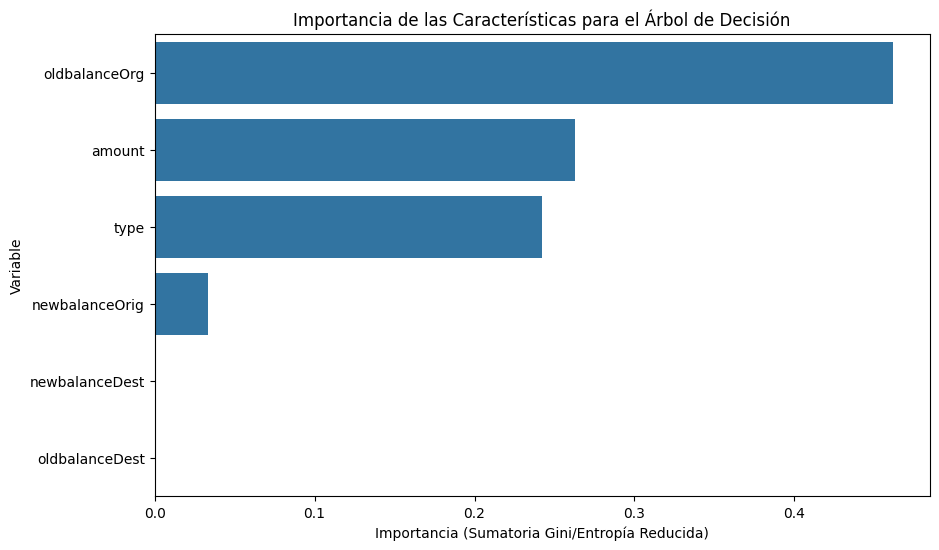

In [ ]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini


--- Generando el Árbol de Decisión Solución ---


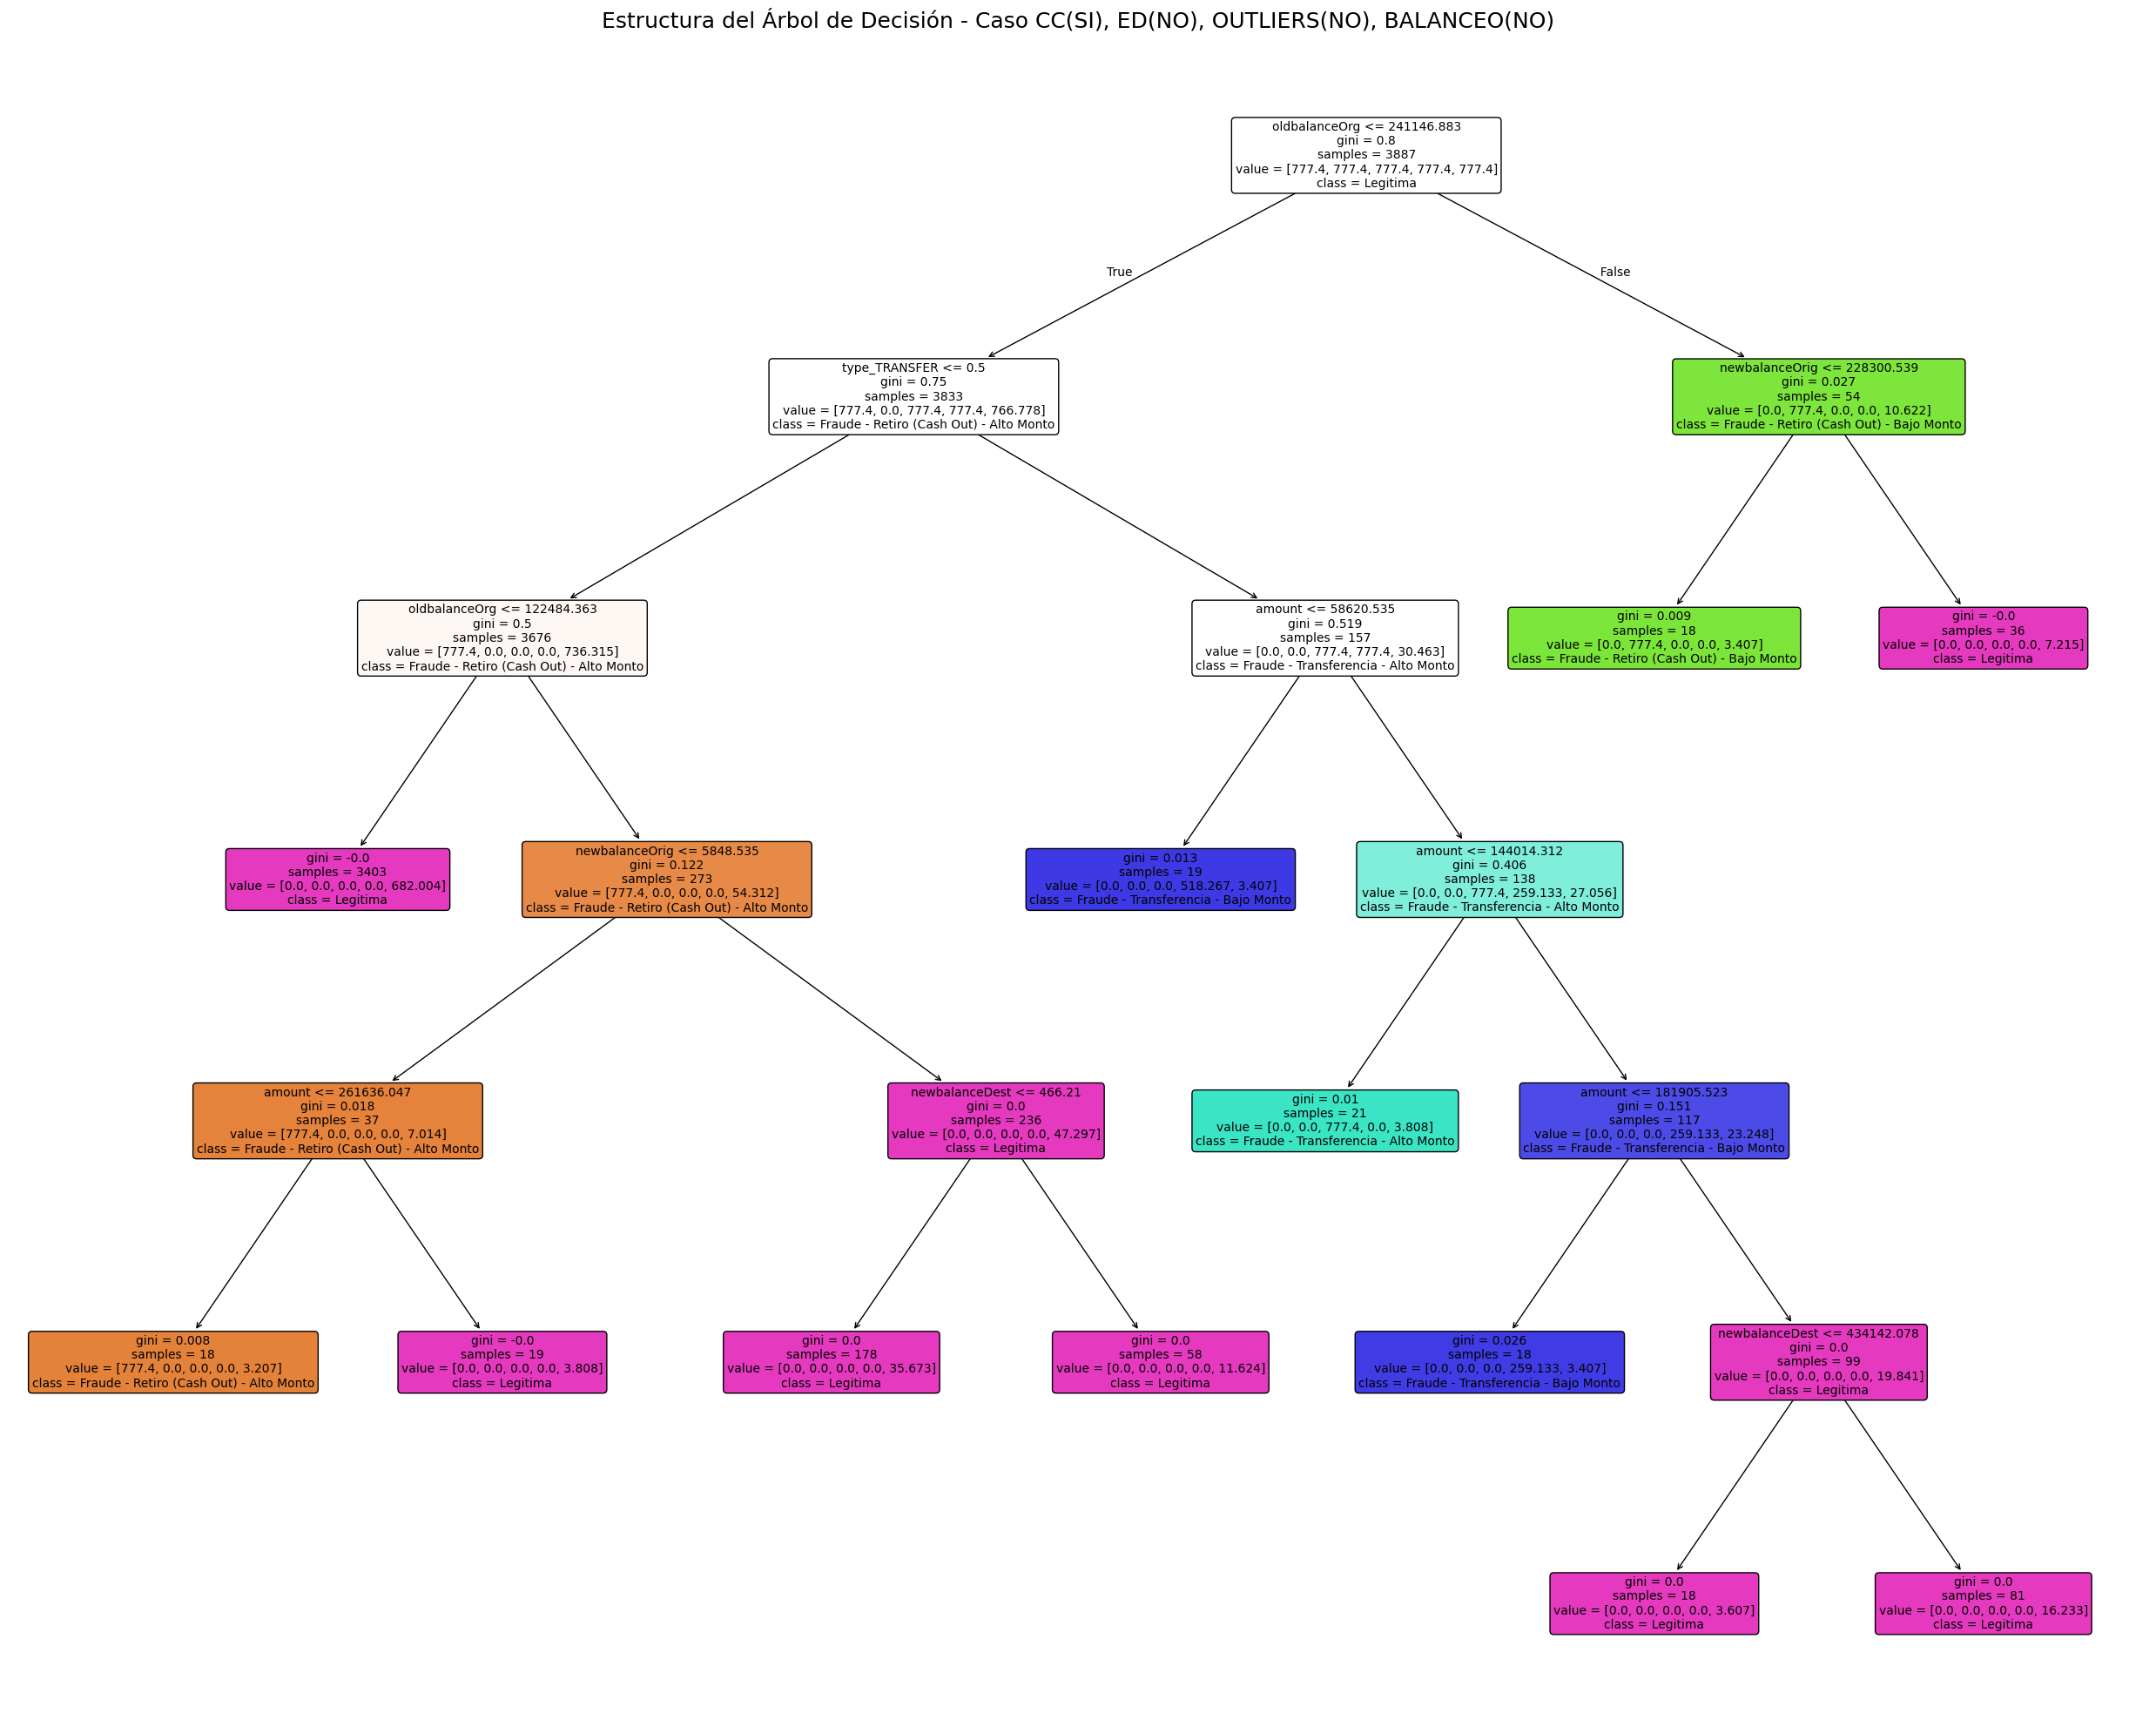

In [ ]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=10            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(NO), OUTLIERS(NO), BALANCEO(NO)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, NO ED, NO OUTLIERS Y SI BALANCEO

In [4]:
df_CC_NO_ED_Balanceado_Sin_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Balanceado_Sin_Outliers.csv')

In [5]:
df_CC_NO_ED_Balanceado_Sin_Outliers['fraud_category_5_classes'].value_counts()

,count
fraud_category_5_classes,
Fraude - Retiro (Cash Out) - Alto Monto,1200
Fraude - Transferencia - Alto Monto,1200
Legitima,1200
Fraude - Transferencia - Bajo Monto,1200
Fraude - Retiro (Cash Out) - Bajo Monto,1200


### Definimos las características (X) y Variable objetivo (y)

In [ ]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_NO_ED_Balanceado_Sin_Outliers.columns if col not in [TARGET_CLASS_5]]

X = df_CC_NO_ED_Balanceado_Sin_Outliers[feature_columns].copy()
y = df_CC_NO_ED_Balanceado_Sin_Outliers[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (6000, 10)
Shape de y: (6000,)
Distribución de y:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Transferencia - Alto Monto        1200
Legitima                                   1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [ ]:
# Dividir los datos 80% para entrenamiento y 20% para prueba
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (4200, 10)
Shape de y_train: (4200,)
Shape de X_test: (1800, 10)
Shape de y_test: (1800,)

Distribución de clases en y_train:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Fraude - Transferencia - Bajo Monto        0.2
Fraude - Transferencia - Alto Monto        0.2
Legitima                                   0.2
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Fraude - Transferencia - Alto Monto        0.2
Legitima                                   0.2
Fraude - Transferencia - Bajo Monto        0.2
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [ ]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
2292    0
2127    3
1498    3
4599    2
4498    0
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
873     2
2034    2
4832    4
649     2
3101    4
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [ ]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
# omitimos class_weight, dado que este data set si está balanceado.

tree_classifier = DecisionTreeClassifier(
    max_depth=17,            # Limita la profundidad
    min_samples_leaf=20,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini'
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")

test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9783

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       1.00      1.00      1.00       360
Fraude - Retiro (Cash Out) - Bajo Monto       1.00      1.00      1.00       360
    Fraude - Transferencia - Alto Monto       0.92      0.98      0.95       360
    Fraude - Transferencia - Bajo Monto       0.97      0.92      0.94       360
                               Legitima       1.00      1.00      1.00       360

                               accuracy                           0.98      1800
                              macro avg       0.98      0.98      0.98      1800
                           weighted avg       0.98      0.98      0.98      1800


--- Matriz de Confusión (Numérica) ---
[[360   0   0   0   0]
 [  0 360   0   0   0]
 [  0   0 352   8   0]
 [  0   0  30 330   0]
 [  0   0   0   1 359]]

AUC-ROC (weighted, One-vs-Rest): 0.9972
AUC-ROC (

### Interpretación de las Métricas de Clasificación

**Accuracy:** 0.9783
Una precisión del 97.83% es ahora un indicador fiable y representativo del rendimiento del modelo.

A diferencia del escenario desbalanceado, esta métrica sí es válida, ya que el conjunto de prueba está balanceado (360 ejemplos por clase).
Esto implica que el modelo acierta de forma consistente en todas las clases, y no solo en la que antes dominaba (Legítima).

**Reporte de Clasificación por Clase:**

**Support:**
Cada clase cuenta con 360 instancias en el conjunto de prueba.
Dataset balanceado.

**Recall (Sensibilidad):**

Fraude - Retiro (Alto/Bajo): 1.00
Detección perfecta. No se escapó ningún caso real de estos tipos de fraude.

Fraude - Transferencia (Alto/Bajo): 0.98 / 0.92
Muy alto. El modelo identificó correctamente la gran mayoría de los casos, con muy pocos fraudes no detectados.

Legítima: 1.00
Identificación completa de transacciones legítimas.

**Precision:**

Fraude - Retiro (Alto/Bajo): 1.00
Precisión perfecta. Toda predicción de estas clases fue correcta, sin falsos positivos.

Fraude - Transferencia (Alto/Bajo): 0.92 / 0.98
Muy alta. Pocas falsas alarmas al predecir estos fraudes.

Legítima: 1.00
Todas las predicciones de transacciones legítimas fueron acertadas.

**F1-score:**

Todos los F1-scores se encuentran entre 0.95 y 1.00, lo que refleja un excelente equilibrio entre precisión y recall en todas las clases, incluso en las minoritarias.

### Casos de Prueba

In [ ]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))





Número total de casos de fraude en y_test: 1440

Índices de las filas que son fraude en X_test:
[873, 2034, 649, 5533, 1091, 2529, 5469, 1179, 3939, 4811, 843, 3138, 5260, 1456, 3113, 5379, 5626, 4289, 692, 105, 5825, 5700, 894, 2539, 182, 1136, 2126, 2327, 1309, 482, 4985, 2741, 3077, 5253, 983, 1550, 458, 2048, 3962, 1219, 5945, 5576, 1942, 5526, 3815, 2303, 284, 5904, 3644, 1744, 2671, 758, 2915, 3996, 3963, 3982, 1107, 4999, 3469, 2621, 2536, 835, 5157, 4160, 5574, 3915, 4877, 2101, 4614, 2899, 2517, 716, 2808, 2361, 5179, 1503, 3765, 868, 3304, 2862, 968, 918, 3059, 616, 4828, 1090, 2046, 4066, 5489, 477, 5859, 2574, 4799, 562, 4792, 4921, 5353, 1389, 4760, 2072, 4837, 4010, 4605, 3670, 3782, 5759, 1988, 3338, 4635, 5206, 881, 3718, 1118, 3449, 1836, 2073, 2444, 4051, 960, 1703, 3508, 2551, 5794, 1485, 2099, 4646, 4445, 70, 2692, 5150, 5940, 1291, 1545, 3, 3426, 1019, 2877, 777, 5921, 1607, 222, 864, 4931, 3407, 4618, 4598, 3906, 1662, 5401, 3925, 2858, 5928, 5739, 5684, 5024, 28

In [ ]:
print("--- Evaluación de Casos de Prueba Seleccionados ---")

# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    681,   # Un caso de no fraude (Legítima)
    1091,   # Un caso de fraude
    5533     # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")


--- Evaluación de Casos de Prueba Seleccionados ---

--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 681) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 1091) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Alto Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Alto Monto

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 5533) ---
  Clase Real (Actual): Fraude - Transferencia - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Transferencia - Bajo Monto


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable  Importancia
3  oldbalanceDest     0.289023
5            type     0.254038
0          amount     0.204534
1   oldbalanceOrg     0.199796
2  newbalanceOrig     0.036241
4  newbalanceDest     0.016367


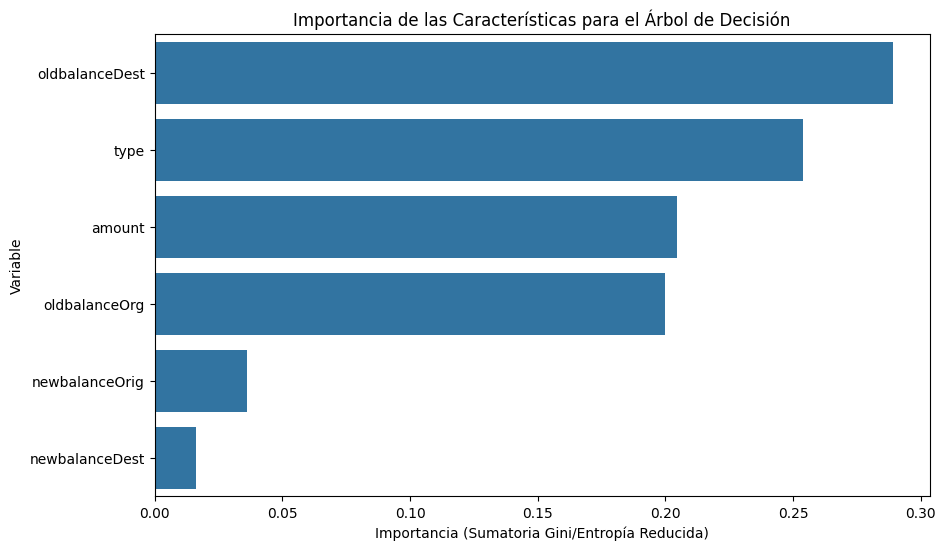

In [ ]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini


--- Generando el Árbol de Decisión Solución ---


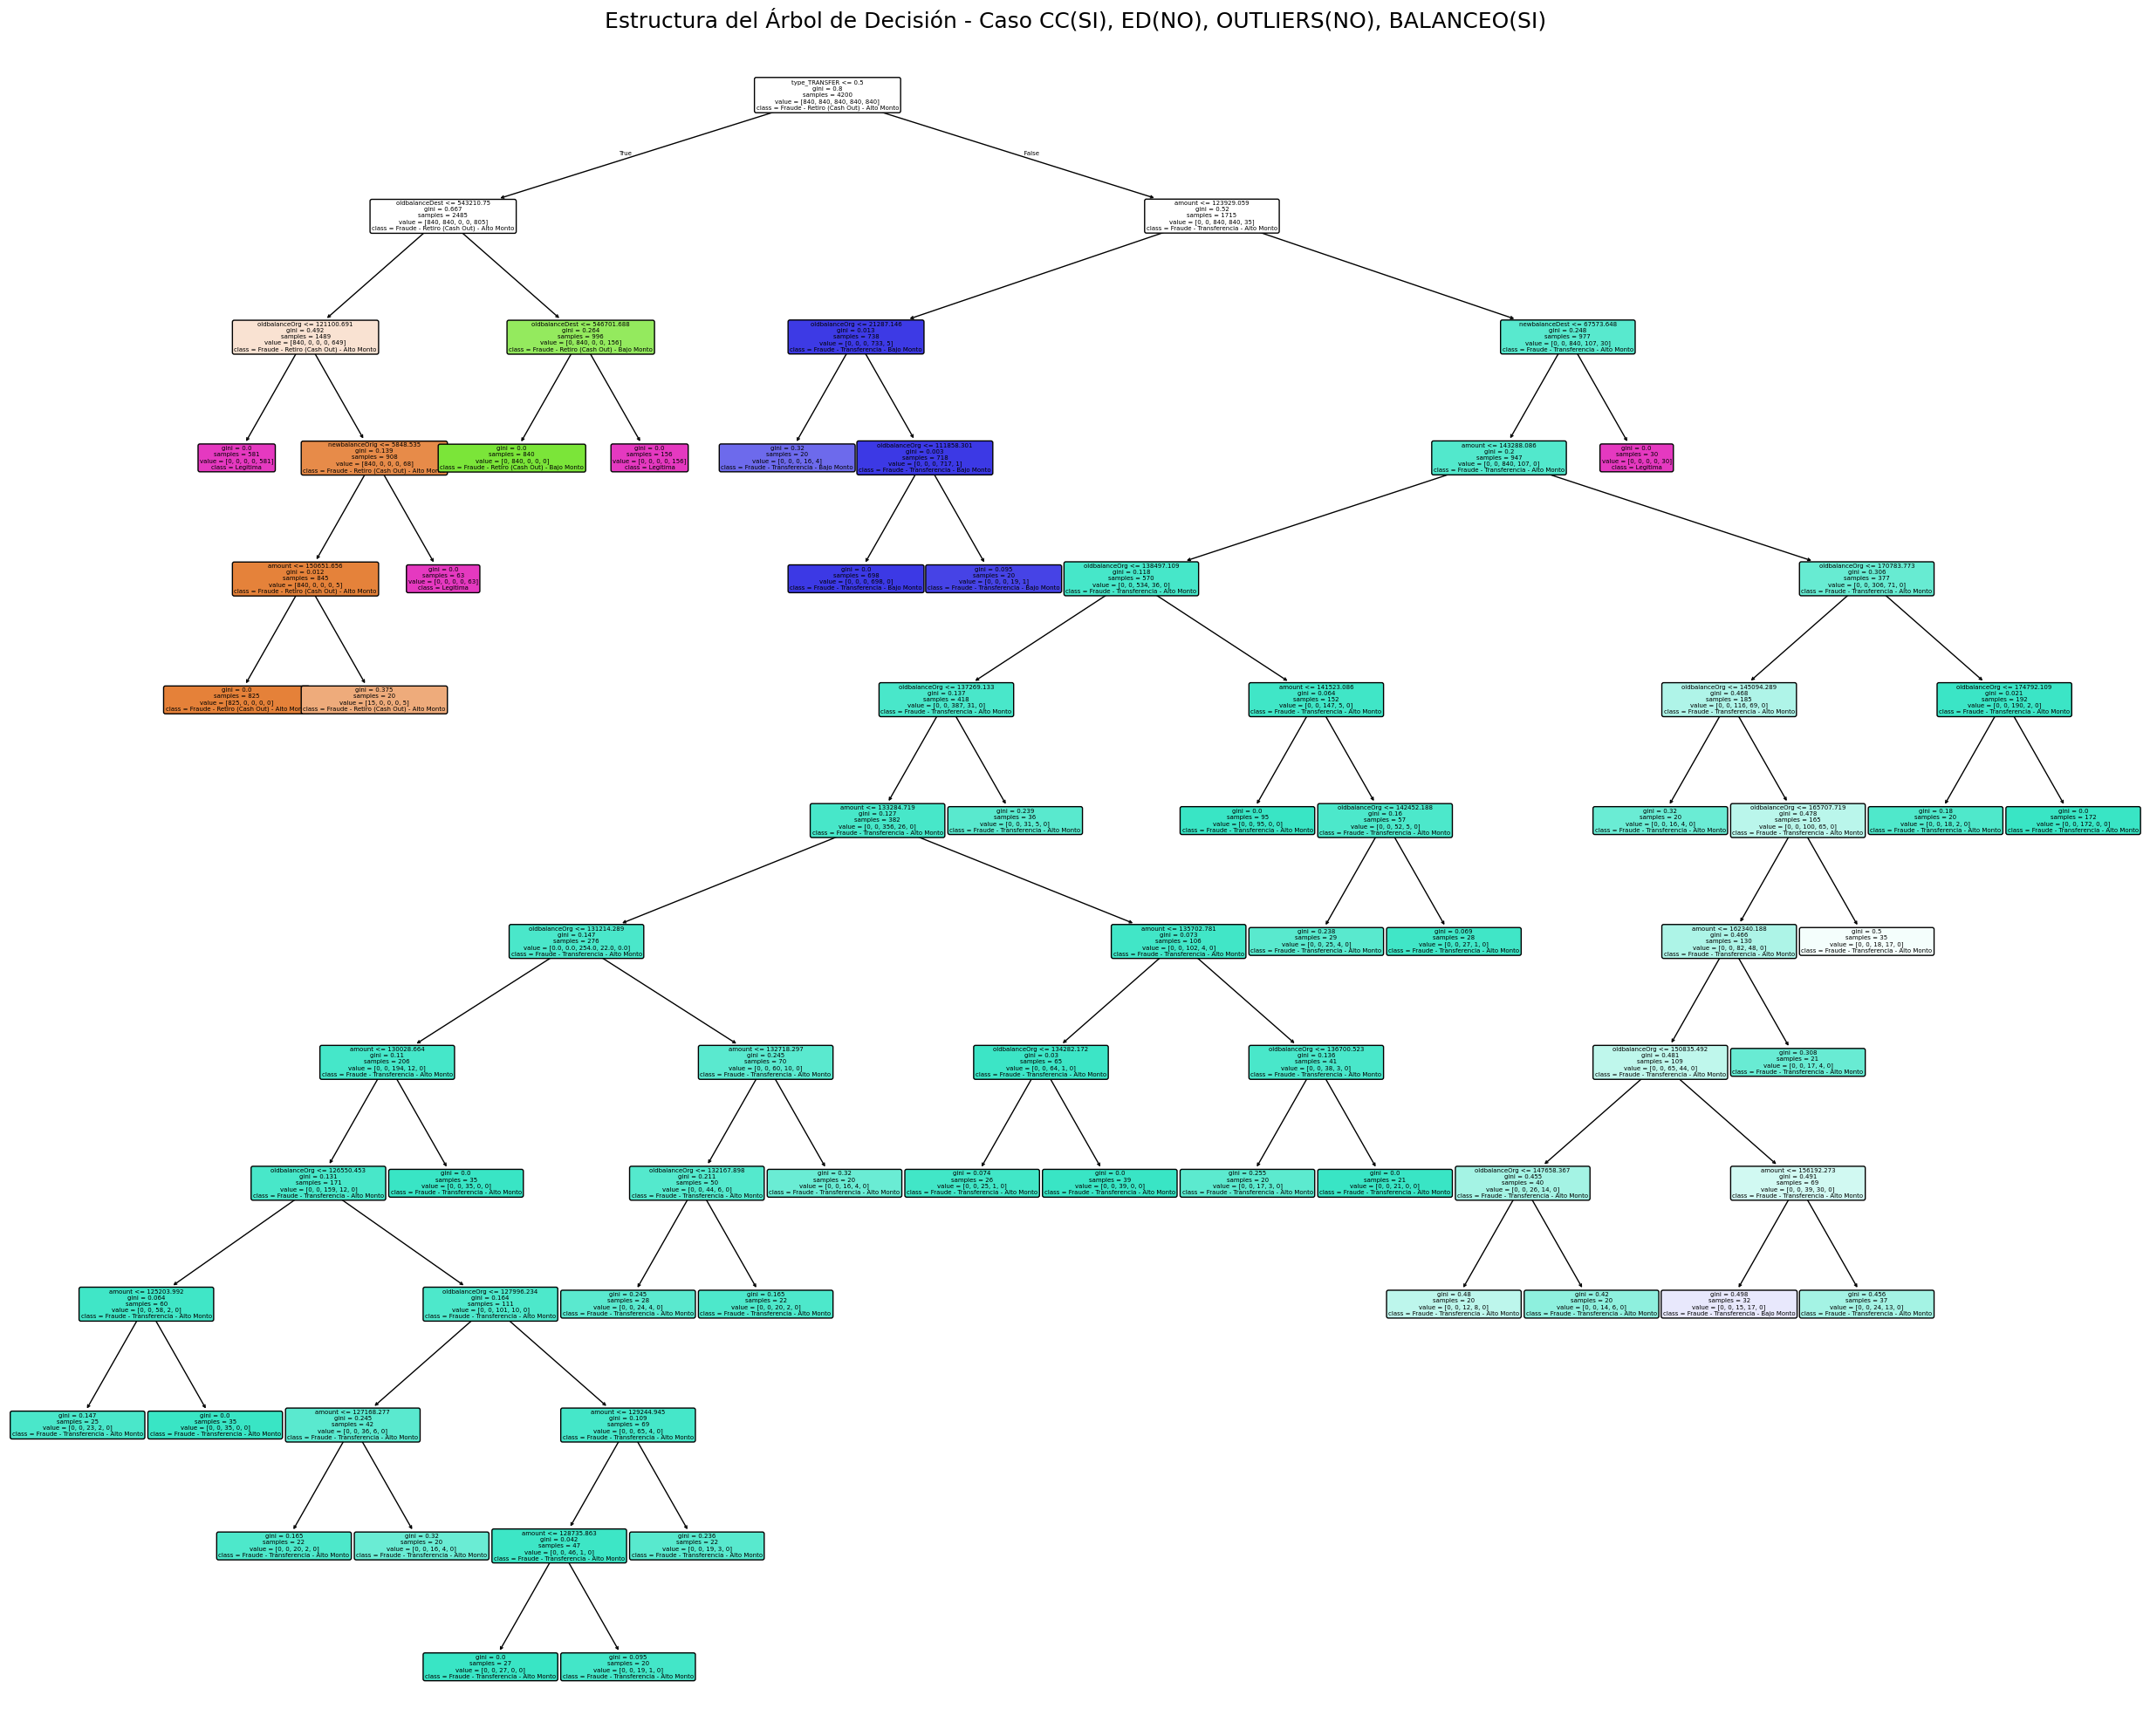

In [ ]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=5            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(NO), OUTLIERS(NO), BALANCEO(SI)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, NO ED, SI OUTLIERS Y NO BALANCEO

In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Desbalanceado_Con_Outliers.csv')

In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   fraud_category_5_classes  8015 non-null   object 
 6   type_CASH_IN              8015 non-null   int64  
 7   type_CASH_OUT             8015 non-null   int64  
 8   type_DEBIT                8015 non-null   int64  
 9   type_PAYMENT              8015 non-null   int64  
 10  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 688.9+ KB


### Definimos las características (X) y Variable objetivo (y)

In [ ]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_NO_ED_Desbalanceado_Con_Outliers.columns if col not in [TARGET_CLASS_5]]

X = df_CC_NO_ED_Desbalanceado_Con_Outliers[feature_columns].copy()
y = df_CC_NO_ED_Desbalanceado_Con_Outliers[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (8015, 10)
Shape de y: (8015,)
Distribución de y:
fraud_category_5_classes
Legitima                                   7989
Fraude - Retiro (Cash Out) - Alto Monto      10
Fraude - Transferencia - Alto Monto           7
Fraude - Retiro (Cash Out) - Bajo Monto       5
Fraude - Transferencia - Bajo Monto           4
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [ ]:
# Dividir los datos 80% para entrenamiento y 20% para prueba
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (6412, 10)
Shape de y_train: (6412,)
Shape de X_test: (1603, 10)
Shape de y_test: (1603,)

Distribución de clases en y_train:
fraud_category_5_classes
Legitima                                   0.996725
Fraude - Retiro (Cash Out) - Alto Monto    0.001248
Fraude - Transferencia - Alto Monto        0.000936
Fraude - Retiro (Cash Out) - Bajo Monto    0.000624
Fraude - Transferencia - Bajo Monto        0.000468
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Legitima                                   0.996881
Fraude - Retiro (Cash Out) - Alto Monto    0.001248
Fraude - Transferencia - Alto Monto        0.000624
Fraude - Retiro (Cash Out) - Bajo Monto    0.000624
Fraude - Transferencia - Bajo Monto        0.000624
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [ ]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
5980    4
2236    4
1122    4
625     4
6530    4
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
771     4
5183    4
2086    4
405     4
5364    4
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [ ]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=15,            # Limita la profundidad
    min_samples_leaf=18,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini',
    class_weight='balanced' # <- usamos este parámetro ya que está desbalanceado el dataset
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9844

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.33      1.00      0.50         2
Fraude - Retiro (Cash Out) - Bajo Monto       0.00      0.00      0.00         1
    Fraude - Transferencia - Alto Monto       0.14      1.00      0.25         1
    Fraude - Transferencia - Bajo Monto       0.20      1.00      0.33         1
                               Legitima       1.00      0.98      0.99      1598

                               accuracy                           0.98      1603
                              macro avg       0.34      0.80      0.42      1603
                           weighted avg       1.00      0.98      0.99      1603


--- Matriz de Confusión (Numérica) ---
[[   2    0    0    0    0]
 [   0    0    0    0    1]
 [   0    0    1    0    0]
 [   0    0    0    1    0]
 [   4   10    6    4 1574]]

AUC-ROC (weighted, One-v

### Interpretación de las Métricas de Clasificación

Al igual que en el primer caso, estamos trabajando con un dataset extremadamente desbalanceado, por lo tanto, el valor elevado de la accuracy puede ser engañoso.

A pesar del Recall de 1.00 para la mayoría de los fraudes, la Precision es extremadamente baja para las clases de fraude (0.33, 0.00, 0.14, 0.20). Esto indica que el modelo está generando una cantidad significativa de Falsos Positivos (FP). Está marcando muchas transacciones legítimas como fraude

macro avg (Precision: 0.34, Recall: 0.80, F1: 0.42): Estos promedios son más realistas para un dataset desbalanceado. Muestran que, en promedio por clase, el modelo tiene un Recall alto (detecta muchos fraudes), pero su Precision y F1-score se ven arrastrados por los Falsos Positivos y la clase que fue completamente perdida

### Casos de Prueba

In [ ]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))





Número total de casos de fraude en y_test: 5

Índices de las filas que son fraude en X_test:
[8000, 8006, 8011, 8003, 7999]

Primeras 5 filas de fraude en X_test:
          amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
8000   338312.05      338312.05             0.0            0.00   
8006    40275.81       40275.81             0.0       545384.07   
8011   122772.73      122772.73             0.0            0.00   
8003  1240633.37     1240633.37             0.0            0.00   
7999    21579.19       21579.19             0.0            0.00   

      newbalanceDest  type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  \
8000            0.00             0              0           0             0   
8006       585659.88             0              1           0             0   
8011       122772.73             0              1           0             0   
8003      1240633.37             0              1           0             0   
7999            0.00             0    

In [ ]:
# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    405,   # Un caso de no fraude (Legítima)
    8003,   # Un caso de fraude
    7999     # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")



--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 405) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 8003) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Alto Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Alto Monto

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 7999) ---
  Clase Real (Actual): Fraude - Transferencia - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Transferencia - Bajo Monto


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable  Importancia
1   oldbalanceOrg     0.349051
5            type     0.237676
3  oldbalanceDest     0.174560
4  newbalanceDest     0.130390
2  newbalanceOrig     0.063425
0          amount     0.044899


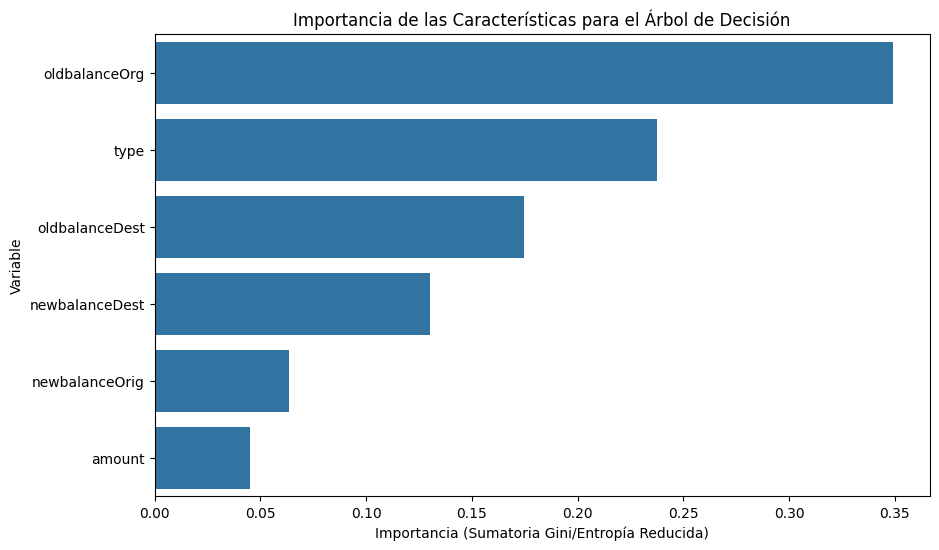

In [ ]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini

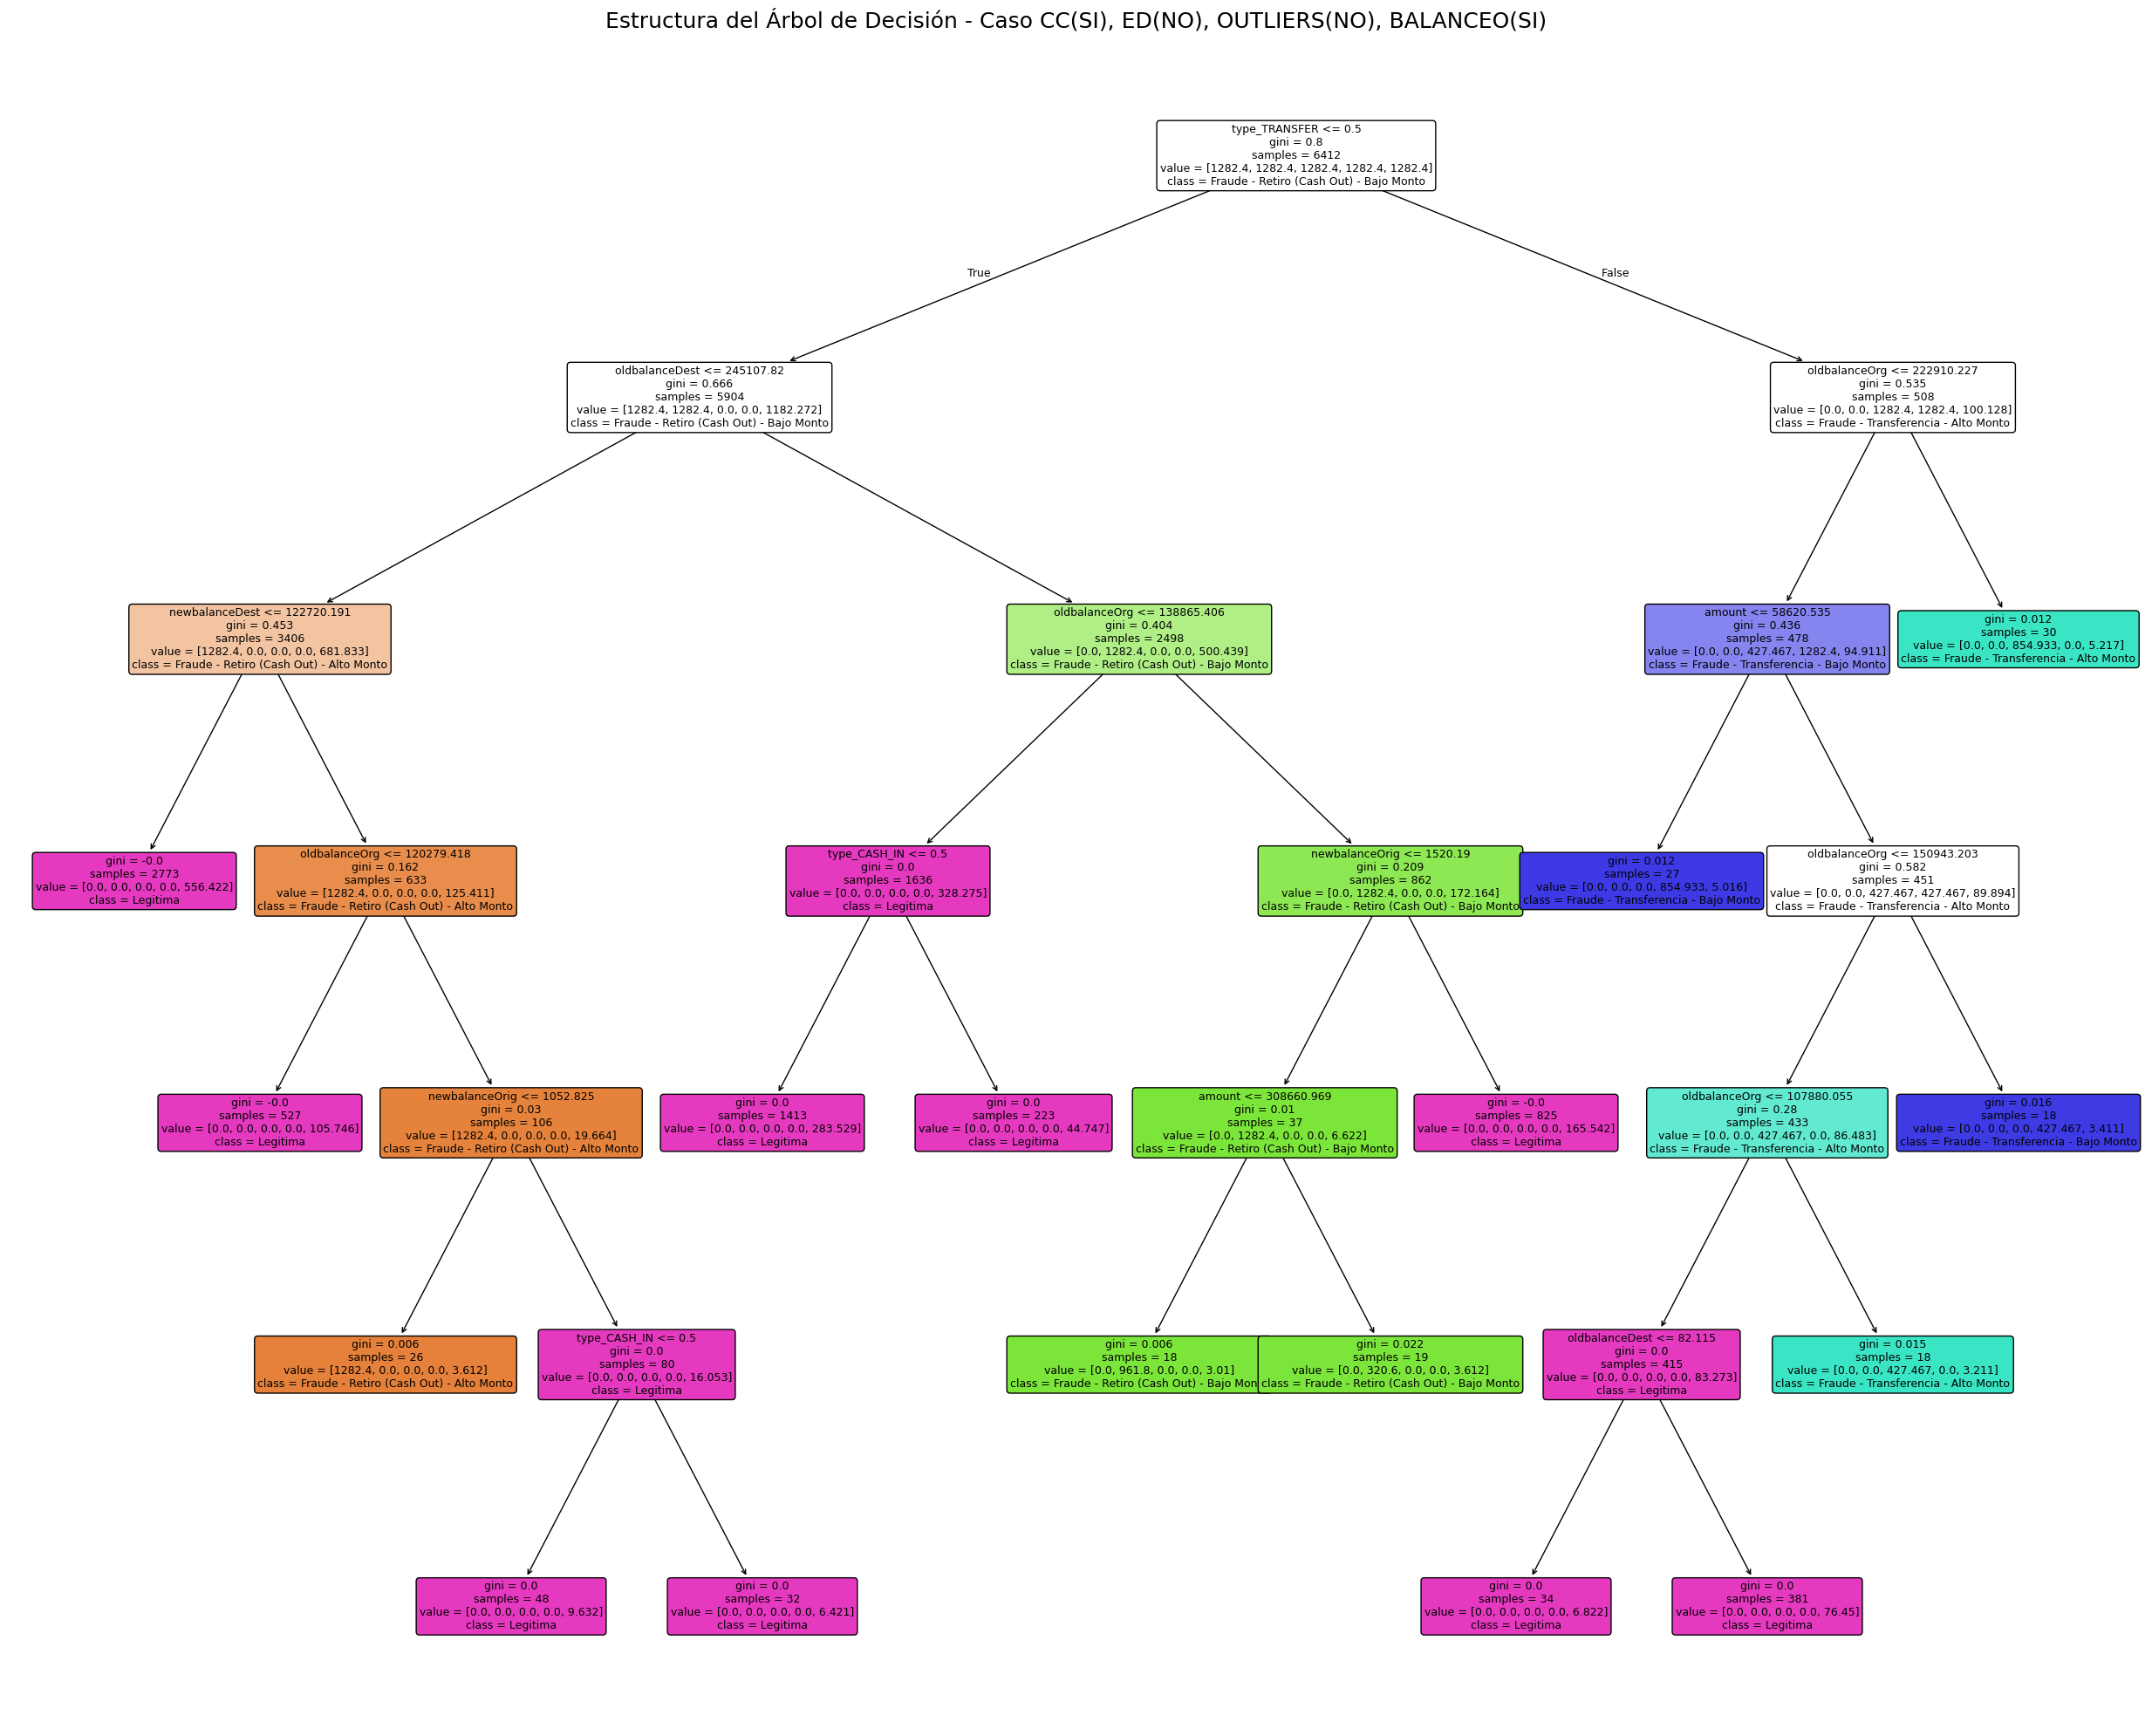

In [ ]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=9            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(NO), OUTLIERS(SI), BALANCEO(NO)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, NO ED, SI OUTLIERS Y SI BALANCEO

In [ ]:
df_CC_NO_ED_Balanceado_Con_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Balanceado_Con_Outliers.csv')

In [ ]:
df_CC_NO_ED_Balanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


### Definimos las características (X) y Variable objetivo (y)

In [ ]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_NO_ED_Balanceado_Con_Outliers.columns if col not in [TARGET_CLASS_5]]

X = df_CC_NO_ED_Balanceado_Con_Outliers[feature_columns].copy()
y = df_CC_NO_ED_Balanceado_Con_Outliers[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (6000, 10)
Shape de y: (6000,)
Distribución de y:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Transferencia - Alto Monto        1200
Legitima                                   1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [ ]:
# Dividir los datos 80% para entrenamiento y 20% para prueba
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (4800, 10)
Shape de y_train: (4800,)
Shape de X_test: (1200, 10)
Shape de y_test: (1200,)

Distribución de clases en y_train:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Legitima                                   0.2
Fraude - Transferencia - Alto Monto        0.2
Fraude - Transferencia - Bajo Monto        0.2
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Fraude - Transferencia - Bajo Monto        0.2
Legitima                                   0.2
Fraude - Transferencia - Alto Monto        0.2
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [ ]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
4988    0
1356    4
4104    2
5872    2
1286    3
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
5680    1
194     1
5836    0
378     1
2333    3
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [ ]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=13,            # Limita la profundidad
    min_samples_leaf=15,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini',
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9783

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       1.00      1.00      1.00       240
Fraude - Retiro (Cash Out) - Bajo Monto       0.99      0.98      0.99       240
    Fraude - Transferencia - Alto Monto       0.96      0.97      0.97       240
    Fraude - Transferencia - Bajo Monto       0.97      0.96      0.96       240
                               Legitima       0.98      0.97      0.98       240

                               accuracy                           0.98      1200
                              macro avg       0.98      0.98      0.98      1200
                           weighted avg       0.98      0.98      0.98      1200


--- Matriz de Confusión (Numérica) ---
[[240   0   0   0   0]
 [  0 236   0   0   4]
 [  0   0 234   6   0]
 [  0   0  10 230   0]
 [  1   3   0   2 234]]

AUC-ROC (weighted, One-vs-Rest): 0.9987
AUC-ROC (

### Interpretación de las Métricas de Clasificación

**Accuracy:** 0.9783
Refleja que el modelo clasifica correctamente casi el 98% de las transacciones en todas las categorías, no solo en la mayoritaria.

**Recall (Sensibilidad):** El modelo muestra una buena capacidad para detectar el fraude, con un Recall superior al 0.96 para todas las clases de fraude. Para "Fraude - Retiro (Cash Out) - Alto Monto", el Recall es perfecto (1.00), significando que todos los casos de este fraude fueron identificados. Esto implica muy pocos Falsos Negativos (fraudes no detectados).

**Precision (Precisión):** La Precision para todas las clases de fraude es también muy alta (superior al 0.96). Esto indica que, cuando el modelo predice un tipo de fraude, es casi siempre correcto, generando un número muy bajo de Falsos Positivos (transacciones legítimas clasificadas erróneamente como fraude)

**F1-score:** Los F1-scores superiores a 0.96 en todas las clases de fraude demuestran un excelente equilibrio entre Precision y Recall.

**macro avg:** (Precision: 0.98, Recall: 0.98, F1: 0.98): Estos promedios son muy altos y confirman el rendimiento consistente y robusto en todas las clases, ya que se promedian las métricas de cada clase sin ponderar por su tamaño.


### Casos de Prueba

In [ ]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))





Número total de casos de fraude en y_test: 960

Índices de las filas que son fraude en X_test:
[5680, 194, 5836, 378, 2333, 310, 4771, 989, 1861, 4203, 3097, 5443, 5013, 112, 3238, 2542, 4444, 945, 4012, 2188, 4402, 5841, 5662, 2064, 2162, 3927, 1747, 5695, 2504, 1098, 987, 1944, 3730, 2202, 1271, 5163, 4621, 3556, 4446, 5437, 1465, 3016, 4801, 1564, 1197, 4616, 5388, 59, 2102, 3754, 3323, 2812, 1029, 2622, 3492, 5399, 5719, 204, 4993, 5835, 959, 3234, 3571, 695, 4340, 2863, 3155, 5465, 208, 625, 3564, 302, 1939, 111, 2537, 4949, 3201, 2763, 5640, 5536, 1497, 329, 2131, 1149, 4464, 1303, 3635, 4947, 3727, 478, 5017, 3272, 2496, 879, 1870, 2008, 5389, 2645, 3198, 3844, 922, 3453, 2457, 2014, 986, 5150, 3362, 5643, 1698, 1282, 4622, 3939, 5346, 4443, 2228, 5095, 4560, 5762, 5988, 5838, 3218, 2666, 3978, 3185, 3873, 1769, 1820, 5616, 258, 5684, 5618, 825, 657, 3367, 2810, 3689, 3111, 2305, 74, 5128, 4234, 4785, 1350, 2617, 2036, 5008, 56, 2336, 3639, 1488, 228, 3215, 5171, 706, 4638, 374

In [ ]:
# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    5289,   # Un caso de no fraude (Legítima)
    5836 ,   # Un caso de fraude
    378     # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")



--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 5289) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 5836) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Alto Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Alto Monto

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 378) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Bajo Monto


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable  Importancia
5            type     0.245754
1   oldbalanceOrg     0.228751
0          amount     0.212989
3  oldbalanceDest     0.180289
2  newbalanceOrig     0.102976
4  newbalanceDest     0.029240


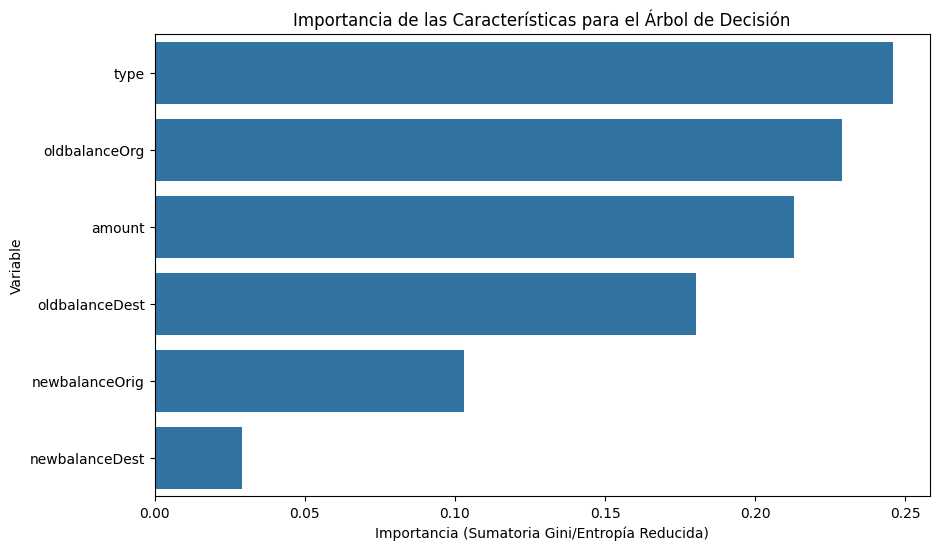

In [ ]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini

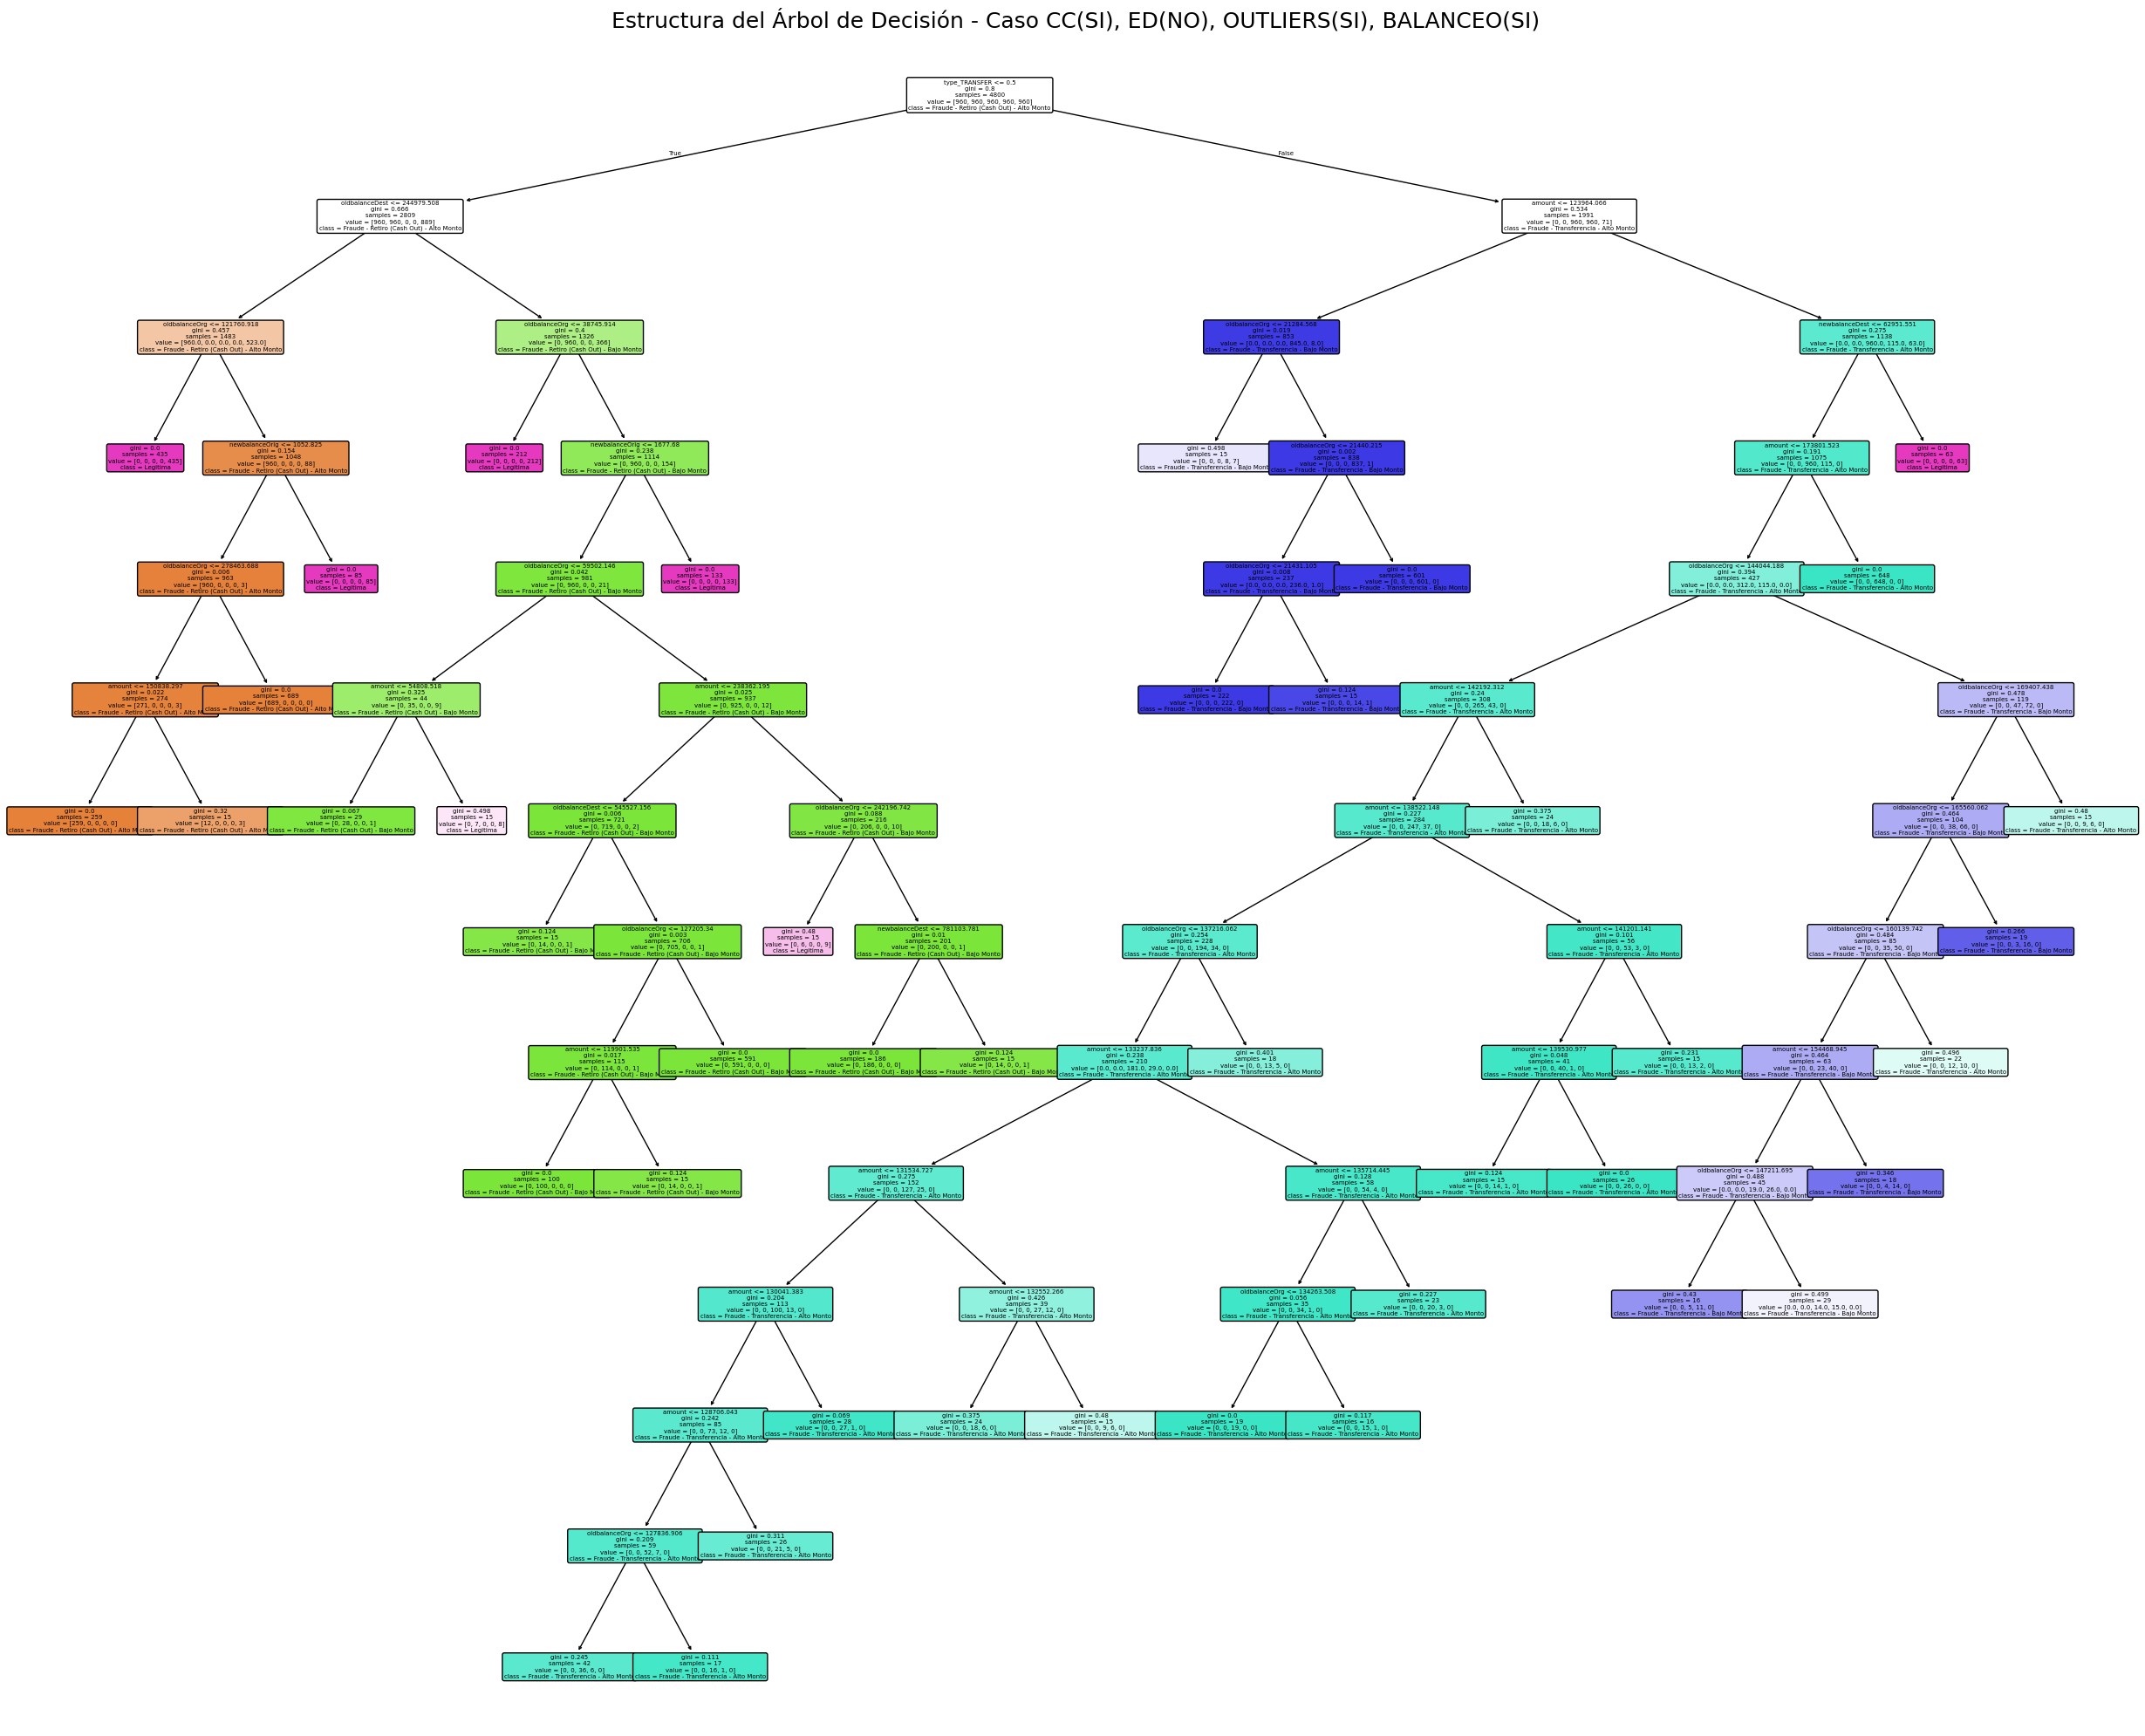

In [ ]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=5            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(NO), OUTLIERS(SI), BALANCEO(SI)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, NO ED, NO OUTLIERS Y NO BALANCEO

In [ ]:
df_CC_SI_ED_Desbalanceado_Sin_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Sin_Outliers.csv')

In [ ]:
df_CC_SI_ED_Desbalanceado_Sin_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5553 entries, 0 to 5552
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    5553 non-null   float64
 1   oldbalanceOrg             5553 non-null   float64
 2   newbalanceOrig            5553 non-null   float64
 3   oldbalanceDest            5553 non-null   float64
 4   newbalanceDest            5553 non-null   float64
 5   fraud_category_5_classes  5553 non-null   object 
 6   type_CASH_IN              5553 non-null   int64  
 7   type_CASH_OUT             5553 non-null   int64  
 8   type_DEBIT                5553 non-null   int64  
 9   type_PAYMENT              5553 non-null   int64  
 10  type_TRANSFER             5553 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 477.3+ KB


### Definimos las características (X) y Variable objetivo (y)

In [ ]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_SI_ED_Desbalanceado_Sin_Outliers.columns if col not in [TARGET_CLASS_5]]

X = df_CC_SI_ED_Desbalanceado_Sin_Outliers[feature_columns].copy()
y = df_CC_SI_ED_Desbalanceado_Sin_Outliers[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (5553, 10)
Shape de y: (5553,)
Distribución de y:
fraud_category_5_classes
Legitima                                   5541
Fraude - Transferencia - Bajo Monto           4
Fraude - Transferencia - Alto Monto           3
Fraude - Retiro (Cash Out) - Alto Monto       3
Fraude - Retiro (Cash Out) - Bajo Monto       2
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [ ]:
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (3887, 10)
Shape de y_train: (3887,)
Shape de X_test: (1666, 10)
Shape de y_test: (1666,)

Distribución de clases en y_train:
fraud_category_5_classes
Legitima                                   0.997942
Fraude - Transferencia - Bajo Monto        0.000772
Fraude - Transferencia - Alto Monto        0.000515
Fraude - Retiro (Cash Out) - Alto Monto    0.000515
Fraude - Retiro (Cash Out) - Bajo Monto    0.000257
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Legitima                                   0.997599
Fraude - Transferencia - Bajo Monto        0.000600
Fraude - Retiro (Cash Out) - Bajo Monto    0.000600
Fraude - Transferencia - Alto Monto        0.000600
Fraude - Retiro (Cash Out) - Alto Monto    0.000600
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [ ]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
658     4
2140    4
5199    4
303     4
243     4
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
2560    4
3275    4
3767    4
1382    4
3376    4
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [ ]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=15,            # Limita la profundidad
    min_samples_leaf=13,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini',
    class_weight='balanced' # <- usamos este parámetro ya que está desbalanceado el dataset
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9766

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.00      0.00      0.00         1
Fraude - Retiro (Cash Out) - Bajo Monto       0.00      0.00      0.00         1
    Fraude - Transferencia - Alto Monto       0.00      0.00      0.00         1
    Fraude - Transferencia - Bajo Monto       0.05      1.00      0.10         1
                               Legitima       1.00      0.98      0.99      1662

                               accuracy                           0.98      1666
                              macro avg       0.21      0.40      0.22      1666
                           weighted avg       1.00      0.98      0.99      1666


--- Matriz de Confusión (Numérica) ---
[[   0    0    0    0    1]
 [   0    0    0    0    1]
 [   0    0    0    1    0]
 [   0    0    0    1    0]
 [   4    7    8   17 1626]]

AUC-ROC (weighted, One-v

### Interpretación de las Métricas de Clasificación

**Accuracy:** 0.9766
Dado que estamos trabajando de nuevo con un dataset desbalanceado en extremo, esta métrica es engañosa.

**Recall (Sensibilidad):** El modelo muestra un Recall de 1.00 solo para la clase "Fraude - Transferencia - Bajo Monto". Sin embargo, para las otras tres clases de fraude (Fraude - Retiro (Cash Out) - Alto Monto/Bajo Monto y Fraude - Transferencia - Alto Monto), el Recall es 0.00. Esto significa que el modelo no detectó la mayoría de los tipos de fraude, generando un número elevado de Falsos Negativos (fraudes no identificados). La clase Legítima mantiene un Recall alto de 0.98.

**Precision (Precisión):** La Precision para la única clase de fraude detectada es extremadamente baja (0.05). Esto indica que, aunque el modelo detectó el único caso real de "Fraude - Transferencia - Bajo Monto", generó una cantidad muy alta de Falsos Positivos (transacciones legítimas clasificadas erróneamente como este tipo de fraude). Para las demás clases de fraude, la Precision es 0.00, lo cual es esperado al no tener Recall.

**macro avg:** (Precision: 0.21, Recall: 0.40, F1: 0.22): Estos promedios son realistas para un dataset desbalanceado. Reflejan el bajo rendimiento del modelo en las clases minoritarias de fraude, indicando que, en promedio, el modelo aún tiene dificultades para clasificar correctamente todos los tipos de transacciones.

### Casos de Prueba

In [ ]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))





Número total de casos de fraude en y_test: 4

Índices de las filas que son fraude en X_test:
[1101, 5549, 2006, 5552]

Primeras 4 filas de fraude en X_test:
        amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
1101 -0.277921      -0.285232       -0.296479       -0.309000       -0.326398   
5549 -0.245333      -0.278626       -0.296479       -0.158798       -0.172595   
2006  0.070814      -0.214542       -0.296479       -0.309000       -0.326398   
5552 -0.105530      -0.250288       -0.296479       -0.309000       -0.294156   

      type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  
1101             0              0           0             0              1  
5549             0              1           0             0              0  
2006             0              0           0             0              1  
5552             0              1           0             0              0  

Primeras 5 filas de no fraude en X_test:
        a

In [ ]:
# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    3767,   # Un caso de no fraude (Legítima)
    5552 ,   # Un caso de fraude
    2006      # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")



--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 3767) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 5552) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Alto Monto
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 2006) ---
  Clase Real (Actual): Fraude - Transferencia - Alto Monto
  Clase Predicha por el Modelo: Fraude - Transferencia - Bajo Monto


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable   Importancia
1   oldbalanceOrg  4.728884e-01
0          amount  2.566678e-01
5            type  2.420055e-01
2  newbalanceOrig  2.843834e-02
4  newbalanceDest  5.232679e-15
3  oldbalanceDest  0.000000e+00


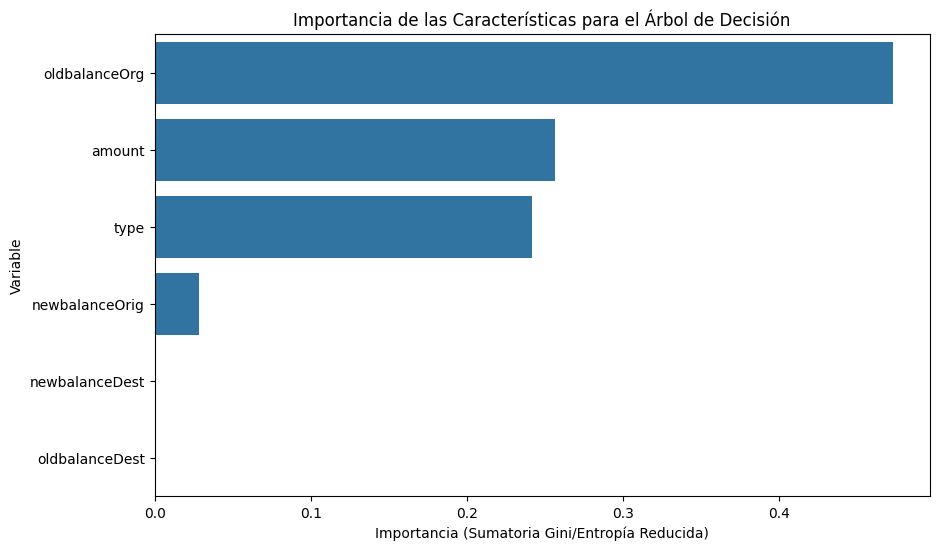

In [ ]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini

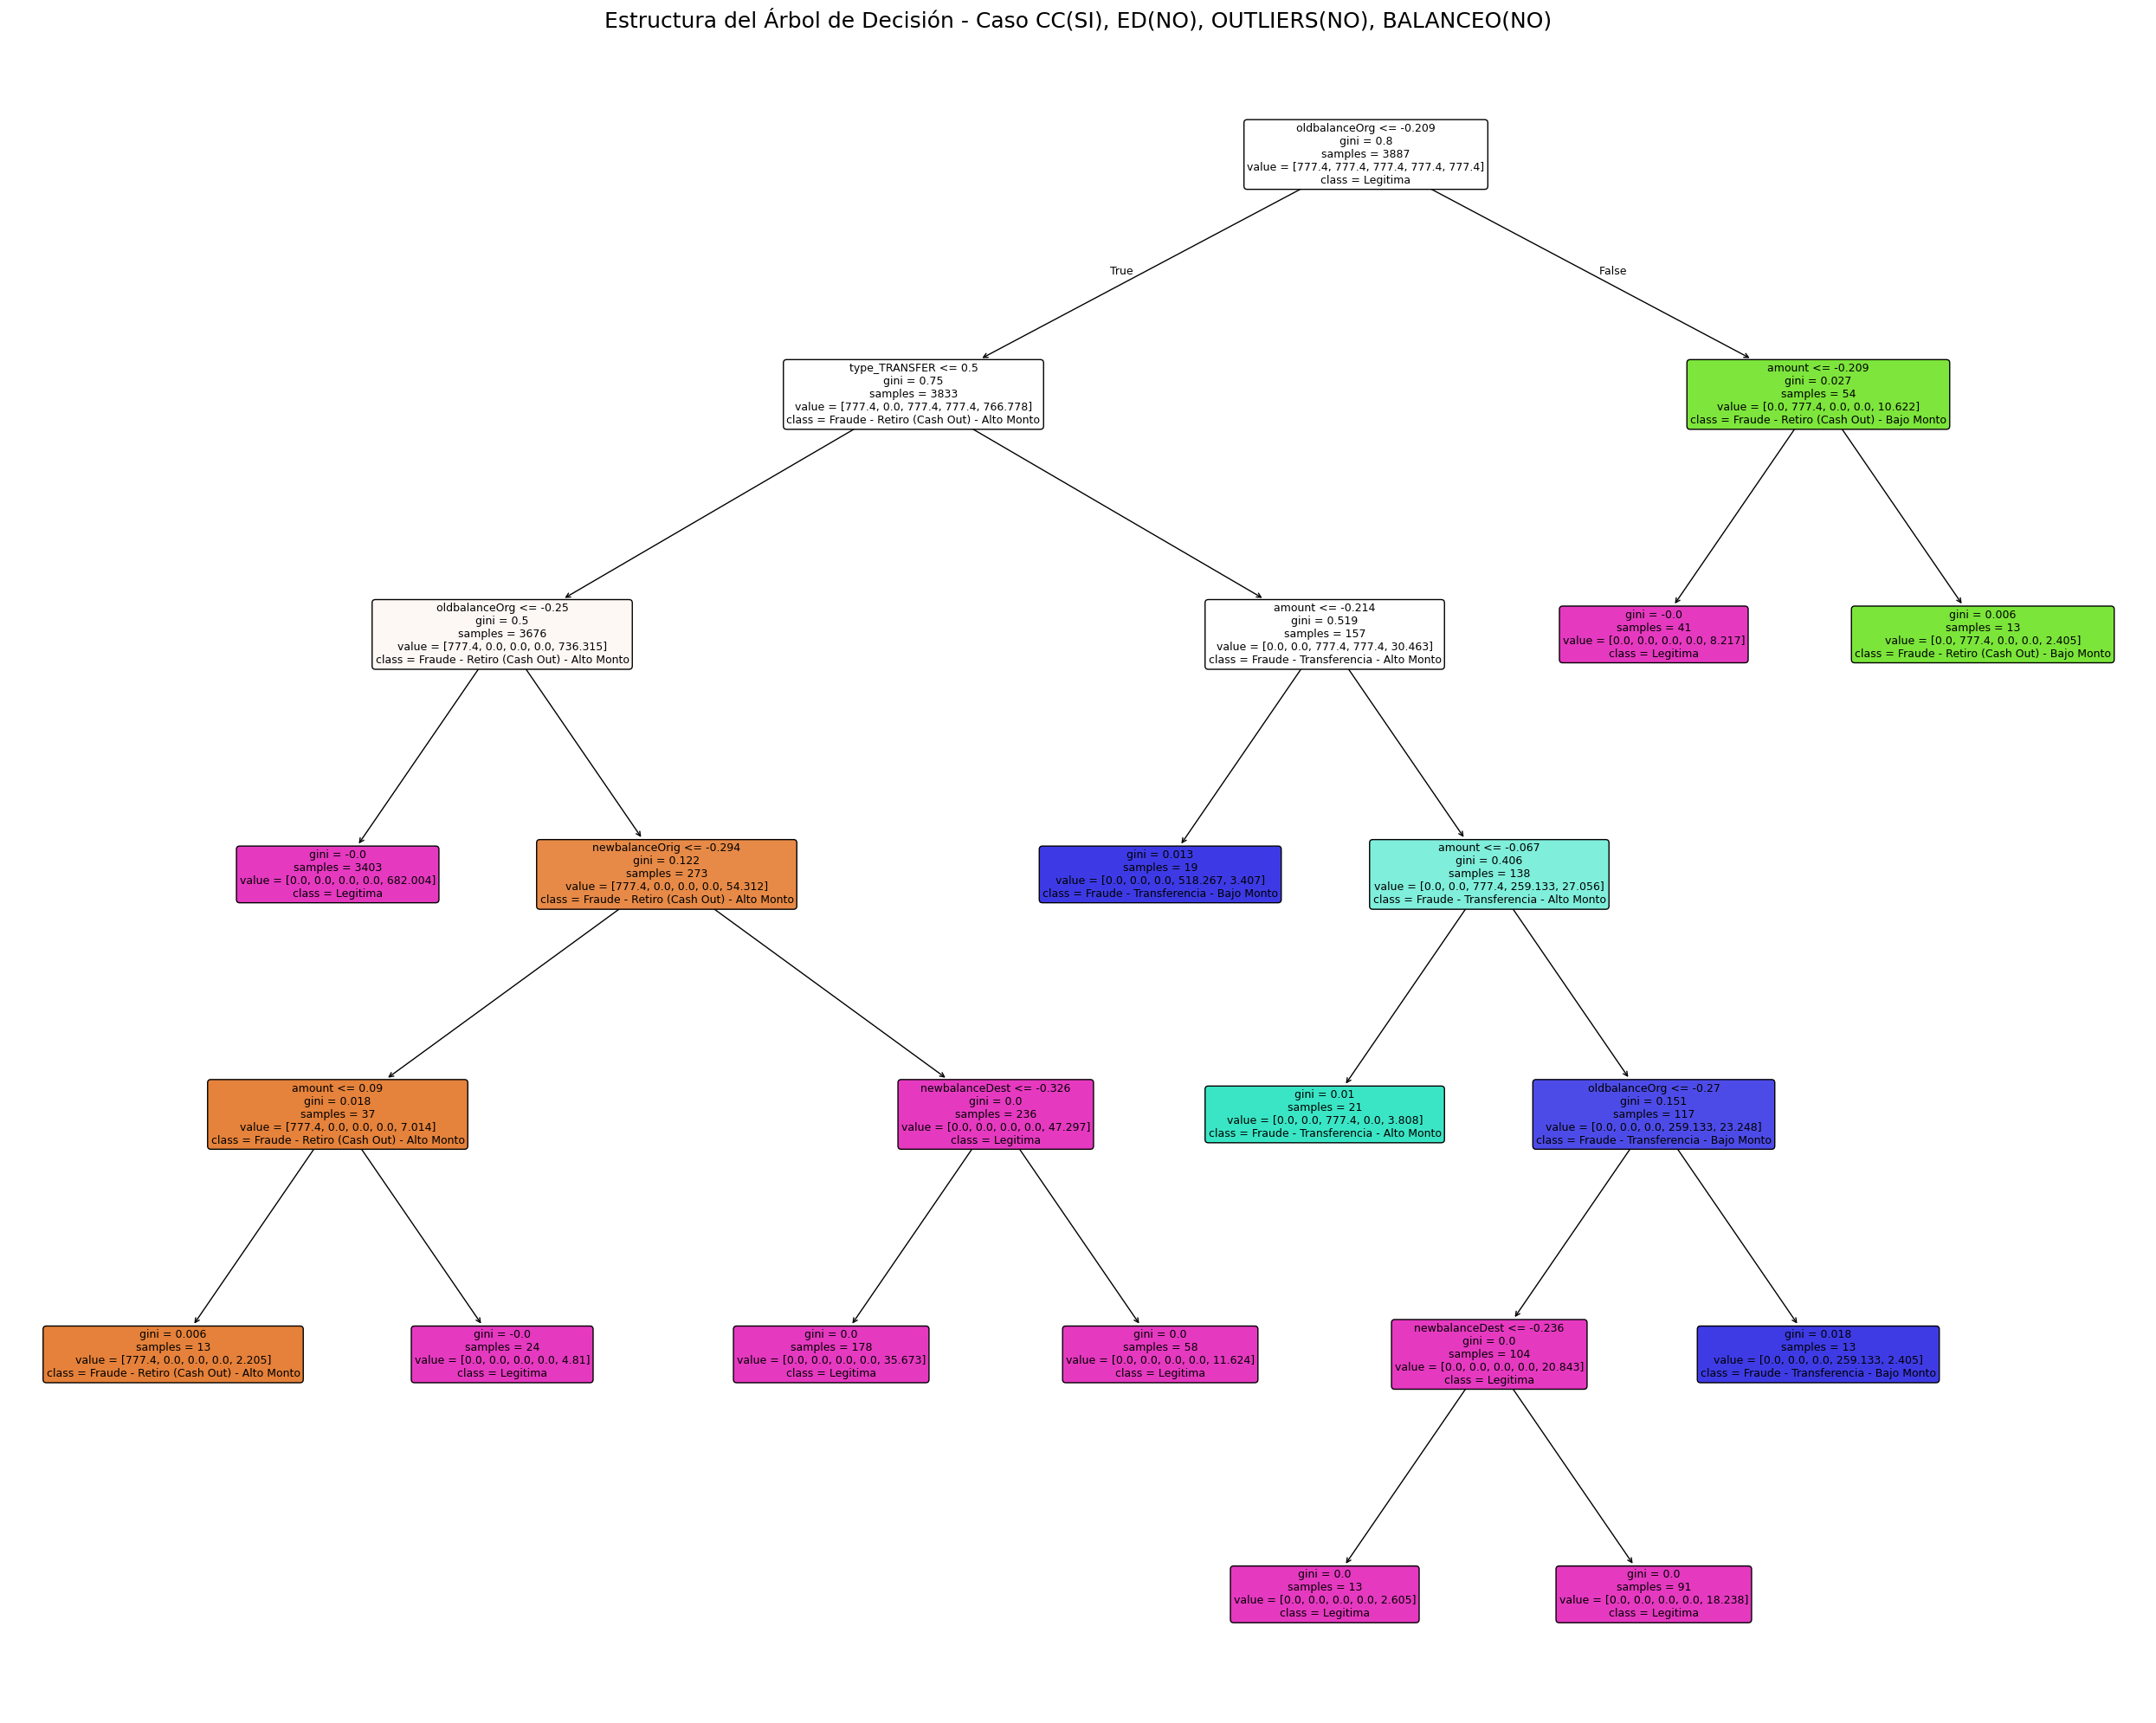

In [ ]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=9            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(NO), OUTLIERS(NO), BALANCEO(NO)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, SI ED, NO OUTLIERS Y SI BALANCEO

In [ ]:
df_CC_SI_ED_Balanceado_Sin_Outlier = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Balanceado_Sin_Outlier.csv')

In [ ]:
df_CC_SI_ED_Balanceado_Sin_Outlier.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


### Definimos las características (X) y Variable objetivo (y)

In [ ]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_SI_ED_Balanceado_Sin_Outlier.columns if col not in [TARGET_CLASS_5]]

X = df_CC_SI_ED_Balanceado_Sin_Outlier[feature_columns].copy()
y = df_CC_SI_ED_Balanceado_Sin_Outlier[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (6000, 10)
Shape de y: (6000,)
Distribución de y:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Transferencia - Alto Monto        1200
Legitima                                   1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [ ]:
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (4800, 10)
Shape de y_train: (4800,)
Shape de X_test: (1200, 10)
Shape de y_test: (1200,)

Distribución de clases en y_train:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Legitima                                   0.2
Fraude - Transferencia - Alto Monto        0.2
Fraude - Transferencia - Bajo Monto        0.2
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Fraude - Transferencia - Bajo Monto        0.2
Legitima                                   0.2
Fraude - Transferencia - Alto Monto        0.2
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [ ]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
4991    0
1356    4
4130    2
5872    2
1283    3
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
5680    1
194     1
5836    0
377     1
2328    3
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [ ]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=19,            # Limita la profundidad
    min_samples_leaf=11,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini'
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9692

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       1.00      1.00      1.00       240
Fraude - Retiro (Cash Out) - Bajo Monto       1.00      1.00      1.00       240
    Fraude - Transferencia - Alto Monto       0.92      0.92      0.92       240
    Fraude - Transferencia - Bajo Monto       0.92      0.93      0.92       240
                               Legitima       1.00      1.00      1.00       240

                               accuracy                           0.97      1200
                              macro avg       0.97      0.97      0.97      1200
                           weighted avg       0.97      0.97      0.97      1200


--- Matriz de Confusión (Numérica) ---
[[240   0   0   0   0]
 [  0 240   0   0   0]
 [  0   0 221  19   0]
 [  0   0  18 222   0]
 [  0   0   0   0 240]]

AUC-ROC (weighted, One-vs-Rest): 0.9967
AUC-ROC (

### Interpretación de las Métricas de Clasificación

**Accuracy:** 0.9692
Como lo hemos visto, usando datasets balanceados, esta métrica refleja que el modelo clasifica correctamente casi el 97% de las transacciones en todas las categorías de manera equilibrada

**Recall (Sensibilidad):** El modelo demuestra una excelente capacidad de detección para todas las clases de fraude, con un Recall superior al 0.92. Para los tipos "Fraude - Retiro", el Recall es perfecto (1.00), lo que significa que el modelo detectó todos los casos de estos fraudes, minimizando los Falsos Negativos. La clase Legítima también muestra un Recall perfecto (1.00).

**Precision (Precisión):** La Precision para todas las clases de fraude es muy alta (superior al 0.92). Esto indica que, cuando el modelo predice un tipo de fraude, es casi siempre correcto, generando un número muy bajo de Falsos Positivos (falsas alarmas). Las clases "Fraude - Retiro" y "Legítima" muestran una Precision perfecta (1.00).

**macro avg** (Precision: 0.97, Recall: 0.97, F1: 0.97): Estos promedios son muy altos y confirman el rendimiento consistente y robusto en todas las clases, al promediar las métricas de cada tipo de transacción sin importar su tamaño original.

### Casos de Prueba

In [ ]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))





Número total de casos de fraude en y_test: 960

Índices de las filas que son fraude en X_test:
[5680, 194, 5836, 377, 2328, 307, 4753, 989, 1878, 4203, 3085, 5443, 5013, 112, 3238, 2557, 4460, 947, 4011, 2219, 4402, 5841, 5662, 2046, 2162, 3925, 1755, 5695, 2516, 1095, 987, 1962, 3727, 2192, 1264, 5163, 4622, 3554, 4433, 5437, 1442, 2990, 4792, 1558, 1207, 4618, 5388, 59, 2099, 3751, 3321, 2810, 1026, 2630, 3508, 5399, 5719, 204, 4993, 5835, 960, 3233, 3570, 695, 4340, 2857, 3154, 5465, 210, 624, 3558, 298, 1959, 111, 2537, 4949, 3180, 2744, 5640, 5536, 1501, 338, 2105, 1138, 4464, 1301, 3631, 4947, 3723, 480, 5015, 3252, 2492, 877, 1862, 1988, 5390, 2642, 3193, 3830, 920, 3446, 2457, 2011, 986, 5150, 3350, 5643, 1706, 1277, 4630, 3939, 5353, 4443, 2227, 5095, 4567, 5762, 5988, 5838, 3207, 2661, 3986, 3185, 3873, 1753, 1832, 5616, 255, 5684, 5618, 829, 655, 3364, 2797, 3699, 3094, 2303, 74, 5128, 4205, 4784, 1357, 2621, 2043, 5009, 56, 2320, 3623, 1485, 228, 3239, 5174, 706, 4626, 374

In [ ]:
# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    5289 ,   # Un caso de no fraude (Legítima)
    194 ,   # Un caso de fraude
    2328       # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")



--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 5289) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 194) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Bajo Monto

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 2328) ---
  Clase Real (Actual): Fraude - Transferencia - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Transferencia - Bajo Monto


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable  Importancia
3  oldbalanceDest     0.287449
5            type     0.253172
0          amount     0.207981
1   oldbalanceOrg     0.200549
2  newbalanceOrig     0.036517
4  newbalanceDest     0.014332


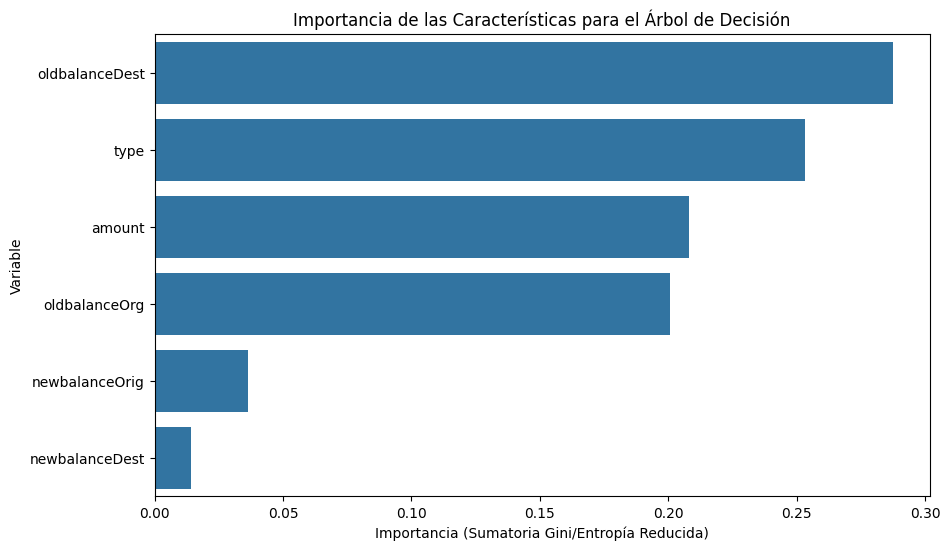

In [ ]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini

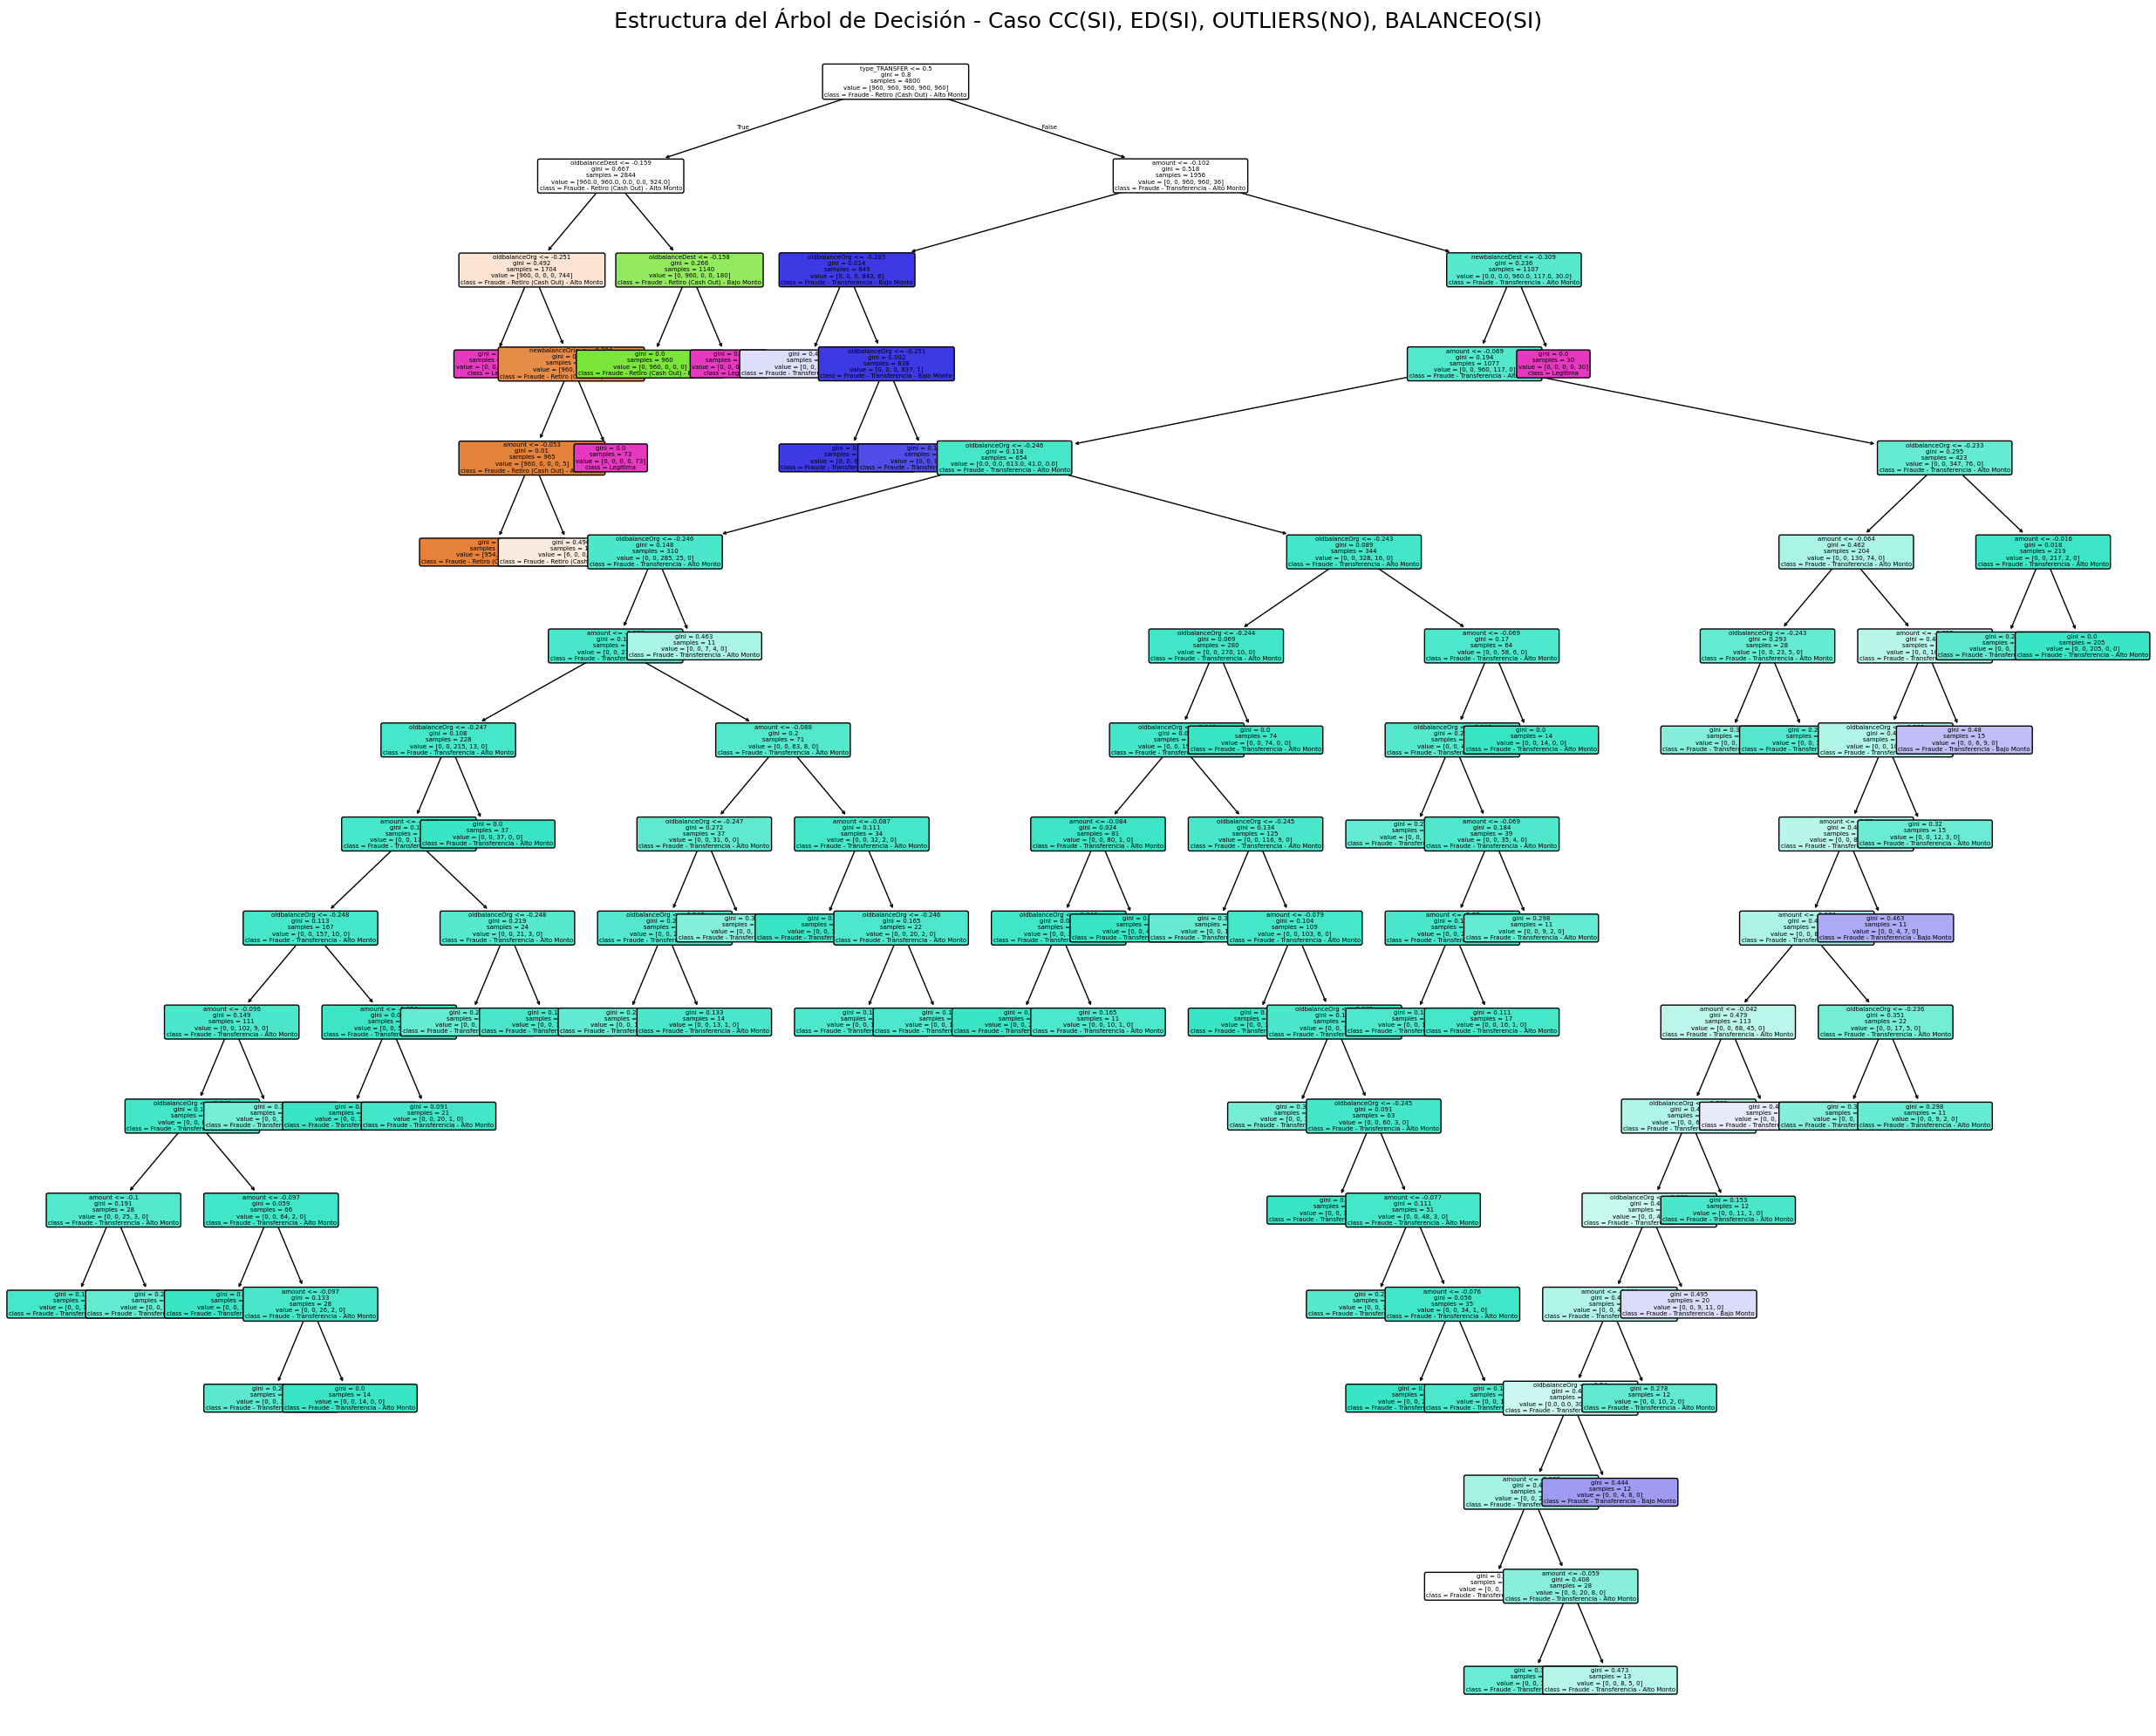

In [ ]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=5            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(SI), OUTLIERS(NO), BALANCEO(SI)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, SI ED, SI OUTLIERS Y NO BALANCEO

In [3]:
# cargamos el dataset:
drive.mount('/content/drive')
df_CC_SI_ED_Desbalanceado_Con_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Con_Outliers.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df_CC_SI_ED_Desbalanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   fraud_category_5_classes  8015 non-null   object 
 6   type_CASH_IN              8015 non-null   int64  
 7   type_CASH_OUT             8015 non-null   int64  
 8   type_DEBIT                8015 non-null   int64  
 9   type_PAYMENT              8015 non-null   int64  
 10  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 688.9+ KB


### Definimos las características (X) y Variable objetivo (y)

In [5]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_SI_ED_Desbalanceado_Con_Outliers.columns if col not in [TARGET_CLASS_5]]

X = df_CC_SI_ED_Desbalanceado_Con_Outliers[feature_columns].copy()
y = df_CC_SI_ED_Desbalanceado_Con_Outliers[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (8015, 10)
Shape de y: (8015,)
Distribución de y:
fraud_category_5_classes
Legitima                                   7989
Fraude - Retiro (Cash Out) - Alto Monto      10
Fraude - Transferencia - Alto Monto           7
Fraude - Retiro (Cash Out) - Bajo Monto       5
Fraude - Transferencia - Bajo Monto           4
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [6]:
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (6412, 10)
Shape de y_train: (6412,)
Shape de X_test: (1603, 10)
Shape de y_test: (1603,)

Distribución de clases en y_train:
fraud_category_5_classes
Legitima                                   0.996725
Fraude - Retiro (Cash Out) - Alto Monto    0.001248
Fraude - Transferencia - Alto Monto        0.000936
Fraude - Retiro (Cash Out) - Bajo Monto    0.000624
Fraude - Transferencia - Bajo Monto        0.000468
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Legitima                                   0.996881
Fraude - Retiro (Cash Out) - Alto Monto    0.001248
Fraude - Transferencia - Alto Monto        0.000624
Fraude - Retiro (Cash Out) - Bajo Monto    0.000624
Fraude - Transferencia - Bajo Monto        0.000624
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [7]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
5980    4
2236    4
1122    4
625     4
6530    4
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
771     4
5183    4
2086    4
405     4
5364    4
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [9]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=16,            # Limita la profundidad
    min_samples_leaf=14,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini',
    class_weight='balanced' # Sirve para darle más peso a la clase minoritaria
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [10]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9838

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.33      1.00      0.50         2
Fraude - Retiro (Cash Out) - Bajo Monto       0.00      0.00      0.00         1
    Fraude - Transferencia - Alto Monto       0.12      1.00      0.22         1
    Fraude - Transferencia - Bajo Monto       0.20      1.00      0.33         1
                               Legitima       1.00      0.98      0.99      1598

                               accuracy                           0.98      1603
                              macro avg       0.33      0.80      0.41      1603
                           weighted avg       1.00      0.98      0.99      1603


--- Matriz de Confusión (Numérica) ---
[[   2    0    0    0    0]
 [   0    0    0    0    1]
 [   0    0    1    0    0]
 [   0    0    0    1    0]
 [   4   10    7    4 1573]]

AUC-ROC (weighted, One-v

### Interpretación de las Métricas de Clasificación

**Accuracy:** 0.9838
Al igual que en otros casos de datasets desbalanceados, el valor elevado de la accuracy es engañoso. Esta métrica refleja principalmente que el modelo clasifica correctamente la vasta mayoría de transacciones legítimas (la clase mayoritaria), lo que no ofrece información útil sobre su capacidad para detectar fraude.

**Recall (Sensibilidad):** El modelo logra un Recall perfecto (1.00) para tres de las cuatro clases de fraude detectadas, incluyendo "Fraude - Retiro (Cash Out) - Alto Monto". Esto indica que, para estos tipos de fraude, el modelo detectó todos los casos reales. Sin embargo, "Fraude - Retiro (Cash Out) - Bajo Monto" tiene un Recall de 0.00, lo que significa que el único caso de este fraude fue completamente omitido. La clase Legítima mantiene un Recall alto de 0.98.

Precision (Precisión): La Precision para las clases de fraude detectadas es muy baja (entre 0.12 y 0.33), mientras que es 0.00 para la no detectada. Esto demuestra que, aunque el modelo es capaz de detectar el fraude (alto Recall), genera una cantidad significativa de Falsos Positivos (transacciones legítimas clasificadas erróneamente como fraude), lo cual reduce la fiabilidad de sus predicciones de fraude.

**macro avg:**(Precision: 0.33, Recall: 0.80, F1: 0.41): Estos promedios son más realistas para un dataset desbalanceado. Reflejan que, en promedio por clase, el modelo tiene un Recall alto, pero su Precision y F1-score se ven arrastrados por los Falsos Positivos y la clase que fue completamente perdida, indicando un rendimiento desequilibrado en la clasificación de todos los tipos de transacciones.

### Casos de Prueba

In [11]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))



Número total de casos de fraude en y_test: 5

Índices de las filas que son fraude en X_test:
[8000, 8006, 8011, 8003, 7999]

Primeras 5 filas de fraude en X_test:
        amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
8000  0.265932      -0.174991       -0.296479       -0.309000       -0.326398   
8006 -0.245333      -0.278626       -0.296479       -0.158798       -0.172595   
8011 -0.103814      -0.249940       -0.296479       -0.309000       -0.294156   
8003  1.813816       0.138770       -0.296479       -0.309000       -0.000590   
7999 -0.277406      -0.285128       -0.296479       -0.309000       -0.326398   

      type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  
8000             0              0           0             0              1  
8006             0              1           0             0              0  
8011             0              1           0             0              0  
8003             0              1        

In [13]:
# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    2328 ,   # Un caso de no fraude (Legítima)
    8011 ,   # Un caso de fraude
    8006       # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")



--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 2328) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 8011) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Alto Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Alto Monto

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 8006) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Bajo Monto
  Clase Predicha por el Modelo: Legitima


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable  Importancia
1   oldbalanceOrg     0.321451
5            type     0.237229
3  oldbalanceDest     0.175484
4  newbalanceDest     0.157710
2  newbalanceOrig     0.063305
0          amount     0.044821


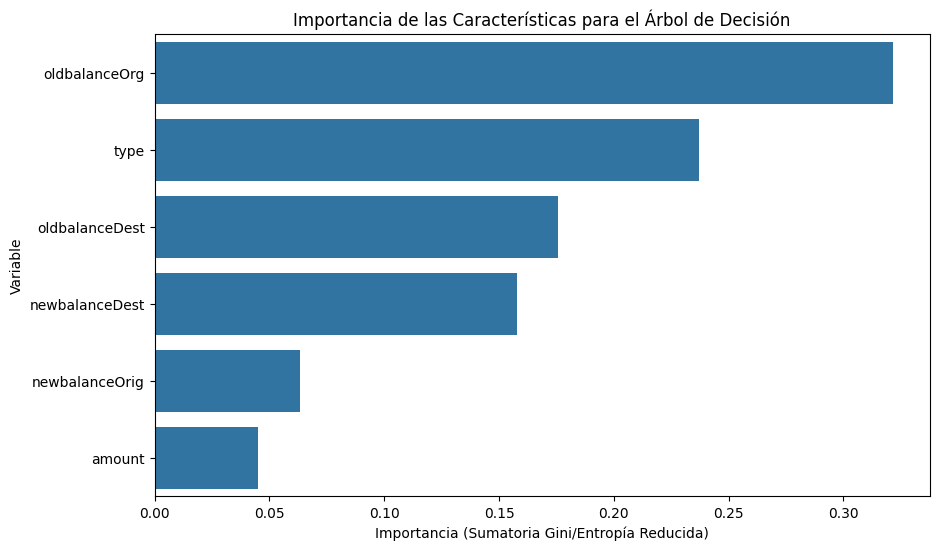

In [14]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini

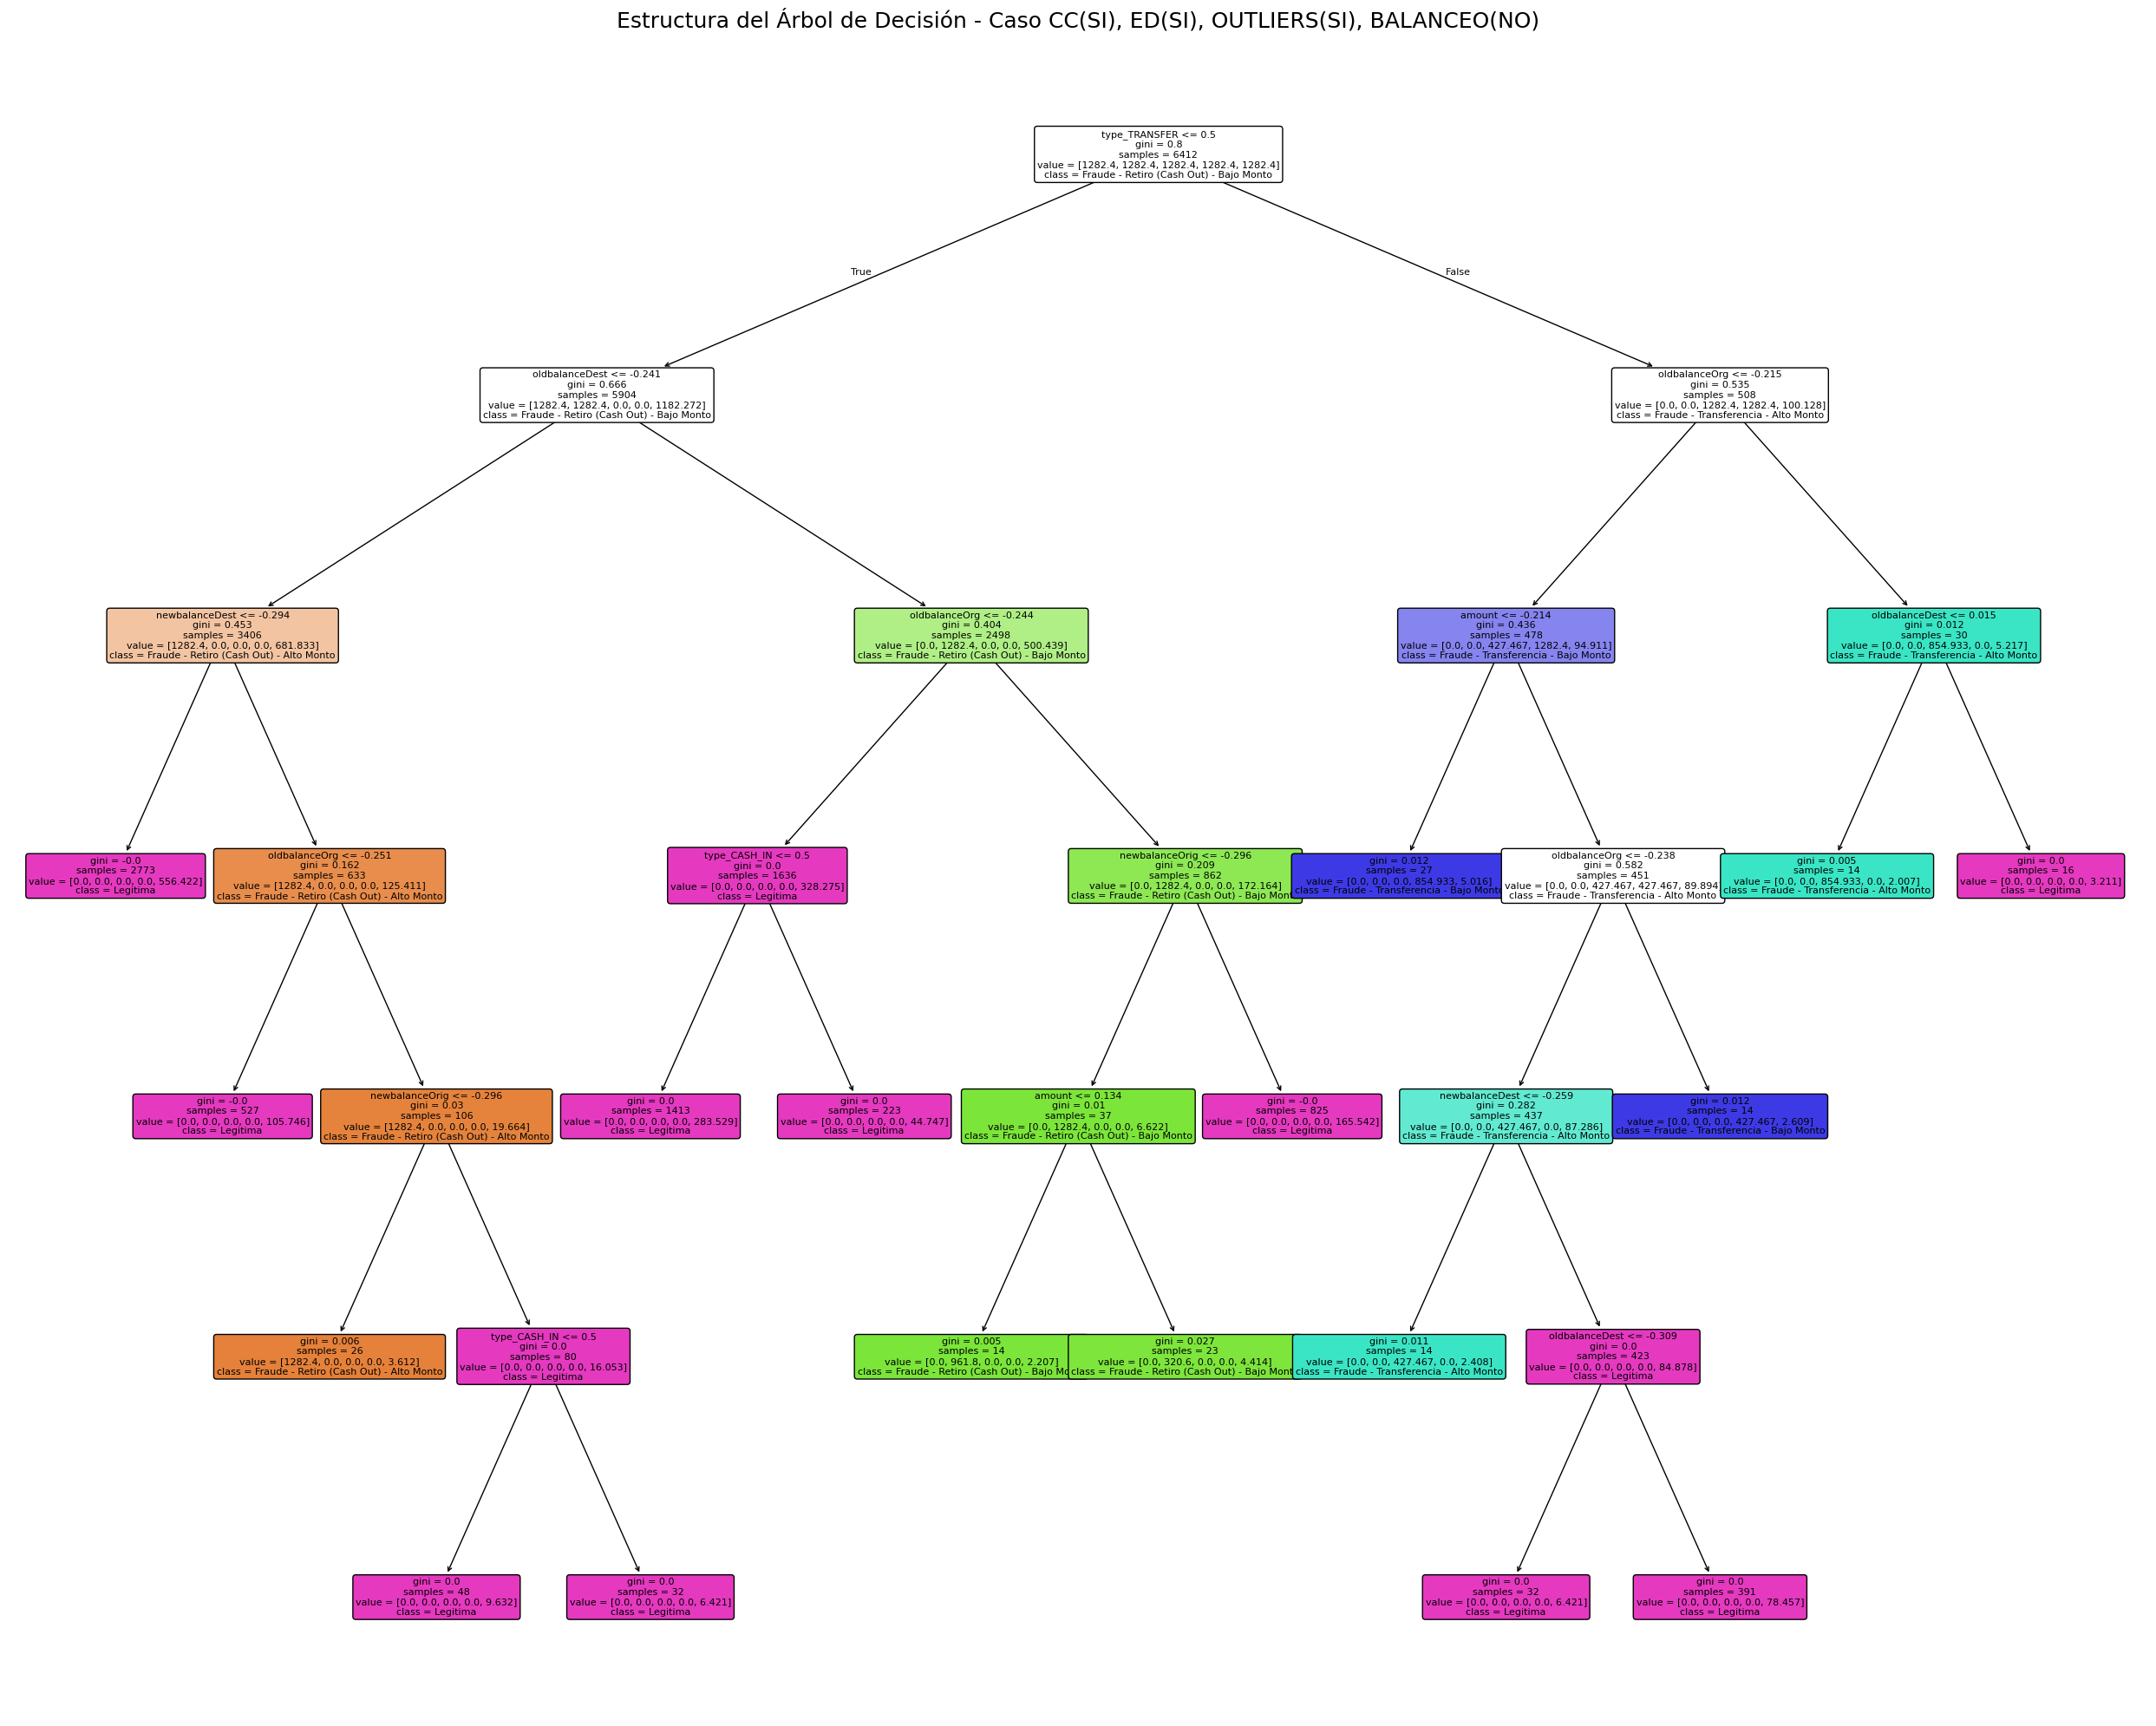

In [16]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=8            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(SI), OUTLIERS(SI), BALANCEO(NO)", fontsize=18)
plt.tight_layout()
plt.show()

# DF CON CC, SI ED, SI OUTLIERS Y SI BALANCEO

In [3]:
df_CC_SI_ED_Balanceado_Con_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Balanceado_Con_Outliers.csv')

In [18]:
df_CC_SI_ED_Balanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


### Definimos las características (X) y Variable objetivo (y)

In [19]:
# Variable objetivo final de 5 clases
TARGET_CLASS_5 = 'fraud_category_5_classes'

# Identificar todas las columnas que serán características (X)
# Es decir, todas las columnas EXCEPTO la variable objetivo de 5 clases
feature_columns = [col for col in df_CC_SI_ED_Balanceado_Con_Outliers.columns if col not in [TARGET_CLASS_5]]

X = df_CC_SI_ED_Balanceado_Con_Outliers[feature_columns].copy()
y = df_CC_SI_ED_Balanceado_Con_Outliers[TARGET_CLASS_5].copy()

print(f"Columnas de X (Características): {X.columns.tolist()}")
print(f"Columna de y (Variable Objetivo): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Distribución de y:\n{y.value_counts()}")

Columnas de X (Características): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Columna de y (Variable Objetivo): fraud_category_5_classes
Shape de X: (6000, 10)
Shape de y: (6000,)
Distribución de y:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Transferencia - Alto Monto        1200
Legitima                                   1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64


### División del Dataset en Conjuntos de Entrenamiento y Prueba (Train/Test Split)

In [20]:
# stratify=y asegura que la proporción de cada una de tus 5 clases se mantenga en ambos conjuntos.
# random_state=42 asegura que la división sea la misma cada vez que ejecutas el código.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Shape de X_train: (4800, 10)
Shape de y_train: (4800,)
Shape de X_test: (1200, 10)
Shape de y_test: (1200,)

Distribución de clases en y_train:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Legitima                                   0.2
Fraude - Transferencia - Alto Monto        0.2
Fraude - Transferencia - Bajo Monto        0.2
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Name: proportion, dtype: float64

Distribución de clases en y_test:
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Bajo Monto    0.2
Fraude - Retiro (Cash Out) - Alto Monto    0.2
Fraude - Transferencia - Bajo Monto        0.2
Legitima                                   0.2
Fraude - Transferencia - Alto Monto        0.2
Name: proportion, dtype: float64


### Preparar la Variable Objetivo y para el Entrenamiento (Mapeo a Números)

In [21]:
# Obtener las clases únicas y ordenarlas para un mapeo consistente
unique_classes_sorted = sorted(y_train.unique())

# Crear un diccionario para mapear nombres de clase a enteros
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
# Crear un diccionario inverso para volver de enteros a nombres de clase (útil para la interpretación)
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}

# Aplicar el mapeo a los conjuntos de entrenamiento y prueba
y_train_numeric = y_train.map(class_to_int_map)
y_test_numeric = y_test.map(class_to_int_map)

print(f"Mapeo de clases: {class_to_int_map}")
print(f"Primeros 5 valores de y_train_numeric:\n{y_train_numeric.head()}")
print(f"Primeros 5 valores de y_test_numeric:\n{y_test_numeric.head()}")

Mapeo de clases: {'Fraude - Retiro (Cash Out) - Alto Monto': 0, 'Fraude - Retiro (Cash Out) - Bajo Monto': 1, 'Fraude - Transferencia - Alto Monto': 2, 'Fraude - Transferencia - Bajo Monto': 3, 'Legitima': 4}
Primeros 5 valores de y_train_numeric:
4988    0
1356    4
4104    2
5872    2
1286    3
Name: fraud_category_5_classes, dtype: int64
Primeros 5 valores de y_test_numeric:
5680    1
194     1
5836    0
378     1
2333    3
Name: fraud_category_5_classes, dtype: int64


### Entrenar el Árbol de Decisión

In [23]:
# Instanciar el modelo de Árbol de Decisión
# Parámetros iniciales para este caso:
# max_depth: Limita la profundidad del árbol para evitar sobreajuste.
# min_samples_leaf: Mínimo de muestras que debe tener una hoja. Ayuda a evitar ramas con muy pocos datos.
# random_state: Para reproducibilidad de resultados.
# criterion: 'gini'
tree_classifier = DecisionTreeClassifier(
    max_depth=18,            # Limita la profundidad
    min_samples_leaf=16,    # Muestras mínimas de cada hoja
    random_state=42,        # Para resultados reproducibles
    criterion='gini'
)

# Entrenar el modelo con los datos de entrenamiento
tree_classifier.fit(X_train, y_train_numeric)

print("Árbol de Decisión entrenado exitosamente.")

Árbol de Decisión entrenado exitosamente.


### Realizar Predicciones y Evaluar el Modelo

In [24]:
# Realizar predicciones en el conjunto de prueba
y_pred_numeric = tree_classifier.predict(X_test)

# Obtener probabilidades de predicción (necesario para AUC-ROC y otras curvas)
# Esto devolverá una matriz donde cada fila es una predicción, y cada columna es la probabilidad de una clase.
y_pred_proba = tree_classifier.predict_proba(X_test)

# Calcular métricas

# Accuracy (Precisión general - Cuidado con desbalance)
accuracy = accuracy_score(y_test_numeric, y_pred_numeric)
print(f"\nAccuracy: {accuracy:.4f}")

# Reporte de Clasificación (Precision, Recall, F1-score por clase)
# Target names deben ser los nombres originales de las clases
print("\n--- Reporte de Clasificación por Clase ---")
# Get the unique labels present in y_test_numeric
test_labels = sorted(y_test_numeric.unique())
print(classification_report(y_test_numeric, y_pred_numeric, target_names=[unique_classes_sorted[i] for i in test_labels], labels=test_labels, zero_division=0))

# Matriz de Confusión
print("\n--- Matriz de Confusión (Numérica) ---")
conf_matrix = confusion_matrix(y_test_numeric, y_pred_numeric)
print(conf_matrix)

# AUC-ROC (para problemas multiclase, se usa OVR - One vs Rest)
# Asegúrate de que todas las clases están presentes en y_test_numeric para el cálculo
try:
    auc_roc_weighted = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='weighted')
    print(f"\nAUC-ROC (weighted, One-vs-Rest): {auc_roc_weighted:.4f}")

    auc_roc_macro = roc_auc_score(y_test_numeric, y_pred_proba, multi_class='ovr', average='macro')
    print(f"AUC-ROC (macro, One-vs-Rest): {auc_roc_macro:.4f}")
except ValueError as e:
    print(f"\nNo se pudo calcular AUC-ROC: {e}. Esto puede ocurrir si alguna clase está ausente en el conjunto de prueba.")
    print("Verifica si todas las clases de fraude están representadas en y_test.")

print("\nEvaluación del Árbol de Decisión completada para este caso.")


Accuracy: 0.9792

--- Reporte de Clasificación por Clase ---
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       1.00      1.00      1.00       240
Fraude - Retiro (Cash Out) - Bajo Monto       0.99      0.98      0.99       240
    Fraude - Transferencia - Alto Monto       0.96      0.97      0.97       240
    Fraude - Transferencia - Bajo Monto       0.97      0.96      0.96       240
                               Legitima       0.98      0.98      0.98       240

                               accuracy                           0.98      1200
                              macro avg       0.98      0.98      0.98      1200
                           weighted avg       0.98      0.98      0.98      1200


--- Matriz de Confusión (Numérica) ---
[[240   0   0   0   0]
 [  0 236   0   0   4]
 [  0   0 234   6   0]
 [  0   0  10 230   0]
 [  1   2   0   2 235]]

AUC-ROC (weighted, One-vs-Rest): 0.9986
AUC-ROC (

### Interpretación de las Métricas de Clasificación

**Accuracy:** 0.9792
Refleja que el modelo clasifica correctamente casi el 98% de las transacciones en todas las categorías de manera equilibrada.

**Recall (Sensibilidad):** El modelo demuestra una buena capacidad de detección para todas las clases de fraude, con un Recall superior al 0.96. Para "Fraude - Retiro (Cash Out) - Alto Monto", el Recall es perfecto (1.00), lo que significa que el modelo detectó todos los casos de este fraude. La clase Legítima también muestra un Recall muy alto (0.98).

**Precision (Precisión):** La Precision para todas las clases de fraude es muy alta (superior al 0.96). Esto indica que, cuando el modelo predice un tipo de fraude, es casi siempre correcto, generando un número muy bajo de Falsos Positivos (falsas alarmas). Las clases "Fraude - Retiro (Cash Out) - Alto Monto" y "Fraude - Retiro (Cash Out) - Bajo Monto" muestran una Precision cercana a la perfección (1.00 y 0.99, respectivamente).

**macro avg:** (Precision: 0.98, Recall: 0.98, F1: 0.98): Estos promedios son muy altos y confirman el rendimiento consistente y bueno en todas las clases, al promediar las métricas de cada tipo de transacción sin importar su tamaño original, no mostramos el weighted avg, ya que, como el dataset está balanceado, entonces, los valores son iguales.

### Casos de Prueba

In [25]:
# 2. Identificamos los nombres de las clases de fraude
# Estas son las 4 clases de fraude que creaste.
fraud_class_names = [
    'Fraude - Retiro (Cash Out) - Alto Monto',
    'Fraude - Retiro (Cash Out) - Bajo Monto',
    'Fraude - Transferencia - Alto Monto',
    'Fraude - Transferencia - Bajo Monto'
]

leg_class_name = 'Legitima'

# 3. Filtrar y_test para obtener solo los casos de fraude
# isin() permite buscar múltiples valores en una Serie
fraud_y_test_series = y_test[y_test.isin(fraud_class_names)]
leg_y_test_series = y_test[y_test == leg_class_name]


# 4. Obtener los índices de las filas que son fraude
fraud_indices = fraud_y_test_series.index.tolist()
leg_indices = leg_y_test_series.index.tolist()

print(f"\nNúmero total de casos de fraude en y_test: {len(fraud_indices)}")

print("\nÍndices de las filas que son fraude en X_test:")
print(fraud_indices)

# 5. Visualizar las filas de fraude y legítimos correspondientes en X_test
# Si hay muchas, solo mostraremos las primeras 5.
print(f"\nPrimeras {min(5, len(fraud_indices))} filas de fraude en X_test:")
print(X_test.loc[fraud_indices].head(5))

print(f"\nPrimeras {min(5, len(leg_indices))} filas de no fraude en X_test:")
print(X_test.loc[leg_indices].head(5))



Número total de casos de fraude en y_test: 960

Índices de las filas que son fraude en X_test:
[5680, 194, 5836, 378, 2333, 310, 4771, 989, 1861, 4203, 3097, 5443, 5013, 112, 3238, 2542, 4444, 945, 4012, 2188, 4402, 5841, 5662, 2064, 2162, 3927, 1747, 5695, 2504, 1098, 987, 1944, 3730, 2202, 1271, 5163, 4621, 3556, 4446, 5437, 1465, 3016, 4801, 1564, 1197, 4616, 5388, 59, 2102, 3754, 3323, 2812, 1029, 2622, 3492, 5399, 5719, 204, 4993, 5835, 959, 3234, 3571, 695, 4340, 2863, 3155, 5465, 208, 625, 3564, 302, 1939, 111, 2537, 4949, 3201, 2763, 5640, 5536, 1497, 329, 2131, 1149, 4464, 1303, 3635, 4947, 3727, 478, 5017, 3272, 2496, 879, 1870, 2008, 5389, 2645, 3198, 3844, 922, 3453, 2457, 2014, 986, 5150, 3362, 5643, 1698, 1282, 4622, 3939, 5346, 4443, 2228, 5095, 4560, 5762, 5988, 5838, 3218, 2666, 3978, 3185, 3873, 1769, 1820, 5616, 258, 5684, 5618, 825, 657, 3367, 2810, 3689, 3111, 2305, 74, 5128, 4234, 4785, 1350, 2617, 2036, 5008, 56, 2336, 3639, 1488, 228, 3215, 5171, 706, 4638, 374

In [26]:
# Selecciona 3 índices concretos 2 de fraude y uno de legítimo:

selected_test_indices = [
    5464 ,   # Un caso de no fraude (Legítima)
    194 ,   # Un caso de fraude
    2333       # Otro caso de fraude
]


# --- PASO 2: Iterar sobre los índices seleccionados y mostrar el análisis para cada uno ---
for i, original_idx in enumerate(selected_test_indices):
    print(f"\n--- ANÁLISIS DEL CASO DE PRUEBA {i+1} (Índice Original en el DataFrame completo: {original_idx}) ---")

    # a. Obtener la fila de características del caso de prueba
    # Usar .loc[[original_idx]] para seleccionar la fila y mantenerla como un DataFrame (2D array)
    # que es el formato que predict() y predict_proba() esperan.
    sample_features = X_test.loc[[original_idx]]

    # b. Obtener la clase REAL (verdad fundamental) de este caso
    actual_class_name = y_test.loc[original_idx]

    # c. Realizar la PREDICCIÓN del modelo
    # .predict() devuelve un array, [0] para obtener el valor escalar
    predicted_numeric = tree_classifier.predict(sample_features)[0]
    predicted_class_name = int_to_class_map.get(predicted_numeric, "Clase Desconocida") # Convertir a nombre

    # d. Obtener las PROBABILIDADES de predicción para todas las clases
    # .predict_proba() devuelve un array de arrays de probabilidades, [0] para la fila del caso
    prediction_proba = tree_classifier.predict_proba(sample_features)[0]

    # e. Mostrar los resultados y comparar
    print(f"  Clase Real (Actual): {actual_class_name}")
    print(f"  Clase Predicha por el Modelo: {predicted_class_name}")



--- ANÁLISIS DEL CASO DE PRUEBA 1 (Índice Original en el DataFrame completo: 5464) ---
  Clase Real (Actual): Legitima
  Clase Predicha por el Modelo: Legitima

--- ANÁLISIS DEL CASO DE PRUEBA 2 (Índice Original en el DataFrame completo: 194) ---
  Clase Real (Actual): Fraude - Retiro (Cash Out) - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Retiro (Cash Out) - Bajo Monto

--- ANÁLISIS DEL CASO DE PRUEBA 3 (Índice Original en el DataFrame completo: 2333) ---
  Clase Real (Actual): Fraude - Transferencia - Bajo Monto
  Clase Predicha por el Modelo: Fraude - Transferencia - Bajo Monto


### Visualización de resultados

Importancia de Características

Importancia de las Características Agrupadas:
         Variable  Importancia
5            type     0.246187
1   oldbalanceOrg     0.227413
0          amount     0.211833
3  oldbalanceDest     0.180572
2  newbalanceOrig     0.102251
4  newbalanceDest     0.031745


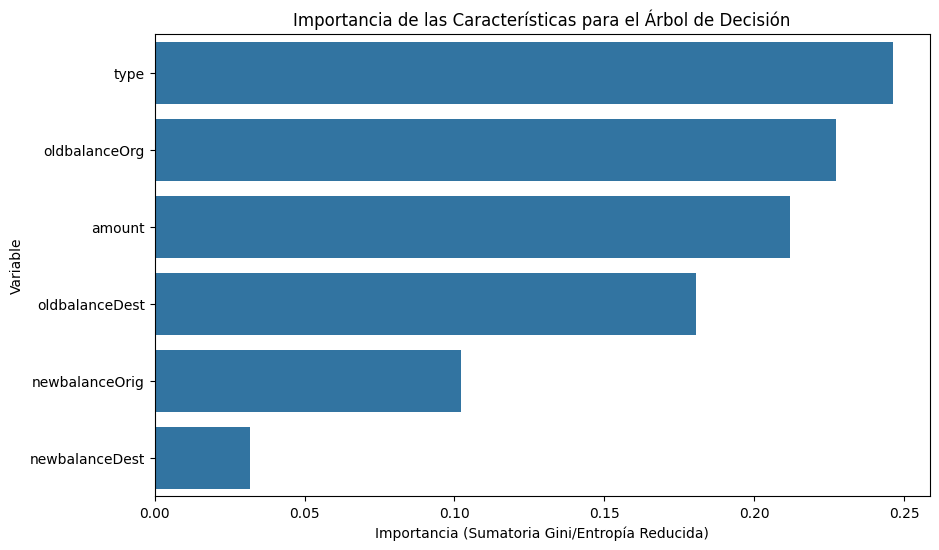

In [27]:
# ==============================================
# Obtenga las caracteristicas mas importantes
# ==============================================

# Crear un defaultdict para agrupar las importancias por nombre de variable original
agrupadas = defaultdict(float)

for feature, importance in zip(X_train.columns, tree_classifier.feature_importances_):
    # Asume que el prefijo antes del "_" es la variable original (ej., 'type_CASH_IN' -> 'type')
    # Si una columna no tiene '_', split('_')[0] devolverá el nombre completo, lo cual es correcto.
    nombre_original = feature.split('_')[0]
    agrupadas[nombre_original] += importance

# Convertir el diccionario agrupado a un DataFrame para una visualización más fácil
importancia_vars = pd.DataFrame({
    'Variable': list(agrupadas.keys()),
    'Importancia': list(agrupadas.values())
}).sort_values(by='Importancia', ascending=False) # Ordenar de mayor a menor importancia

print("Importancia de las Características Agrupadas:")
print(importancia_vars)

# Visualizar la importancia de las características

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=importancia_vars)
plt.title('Importancia de las Características para el Árbol de Decisión')
plt.xlabel('Importancia (Sumatoria Gini/Entropía Reducida)')
plt.ylabel('Variable')
plt.show()

Gráfico del árbol de decisión solución usando el criterio Gini

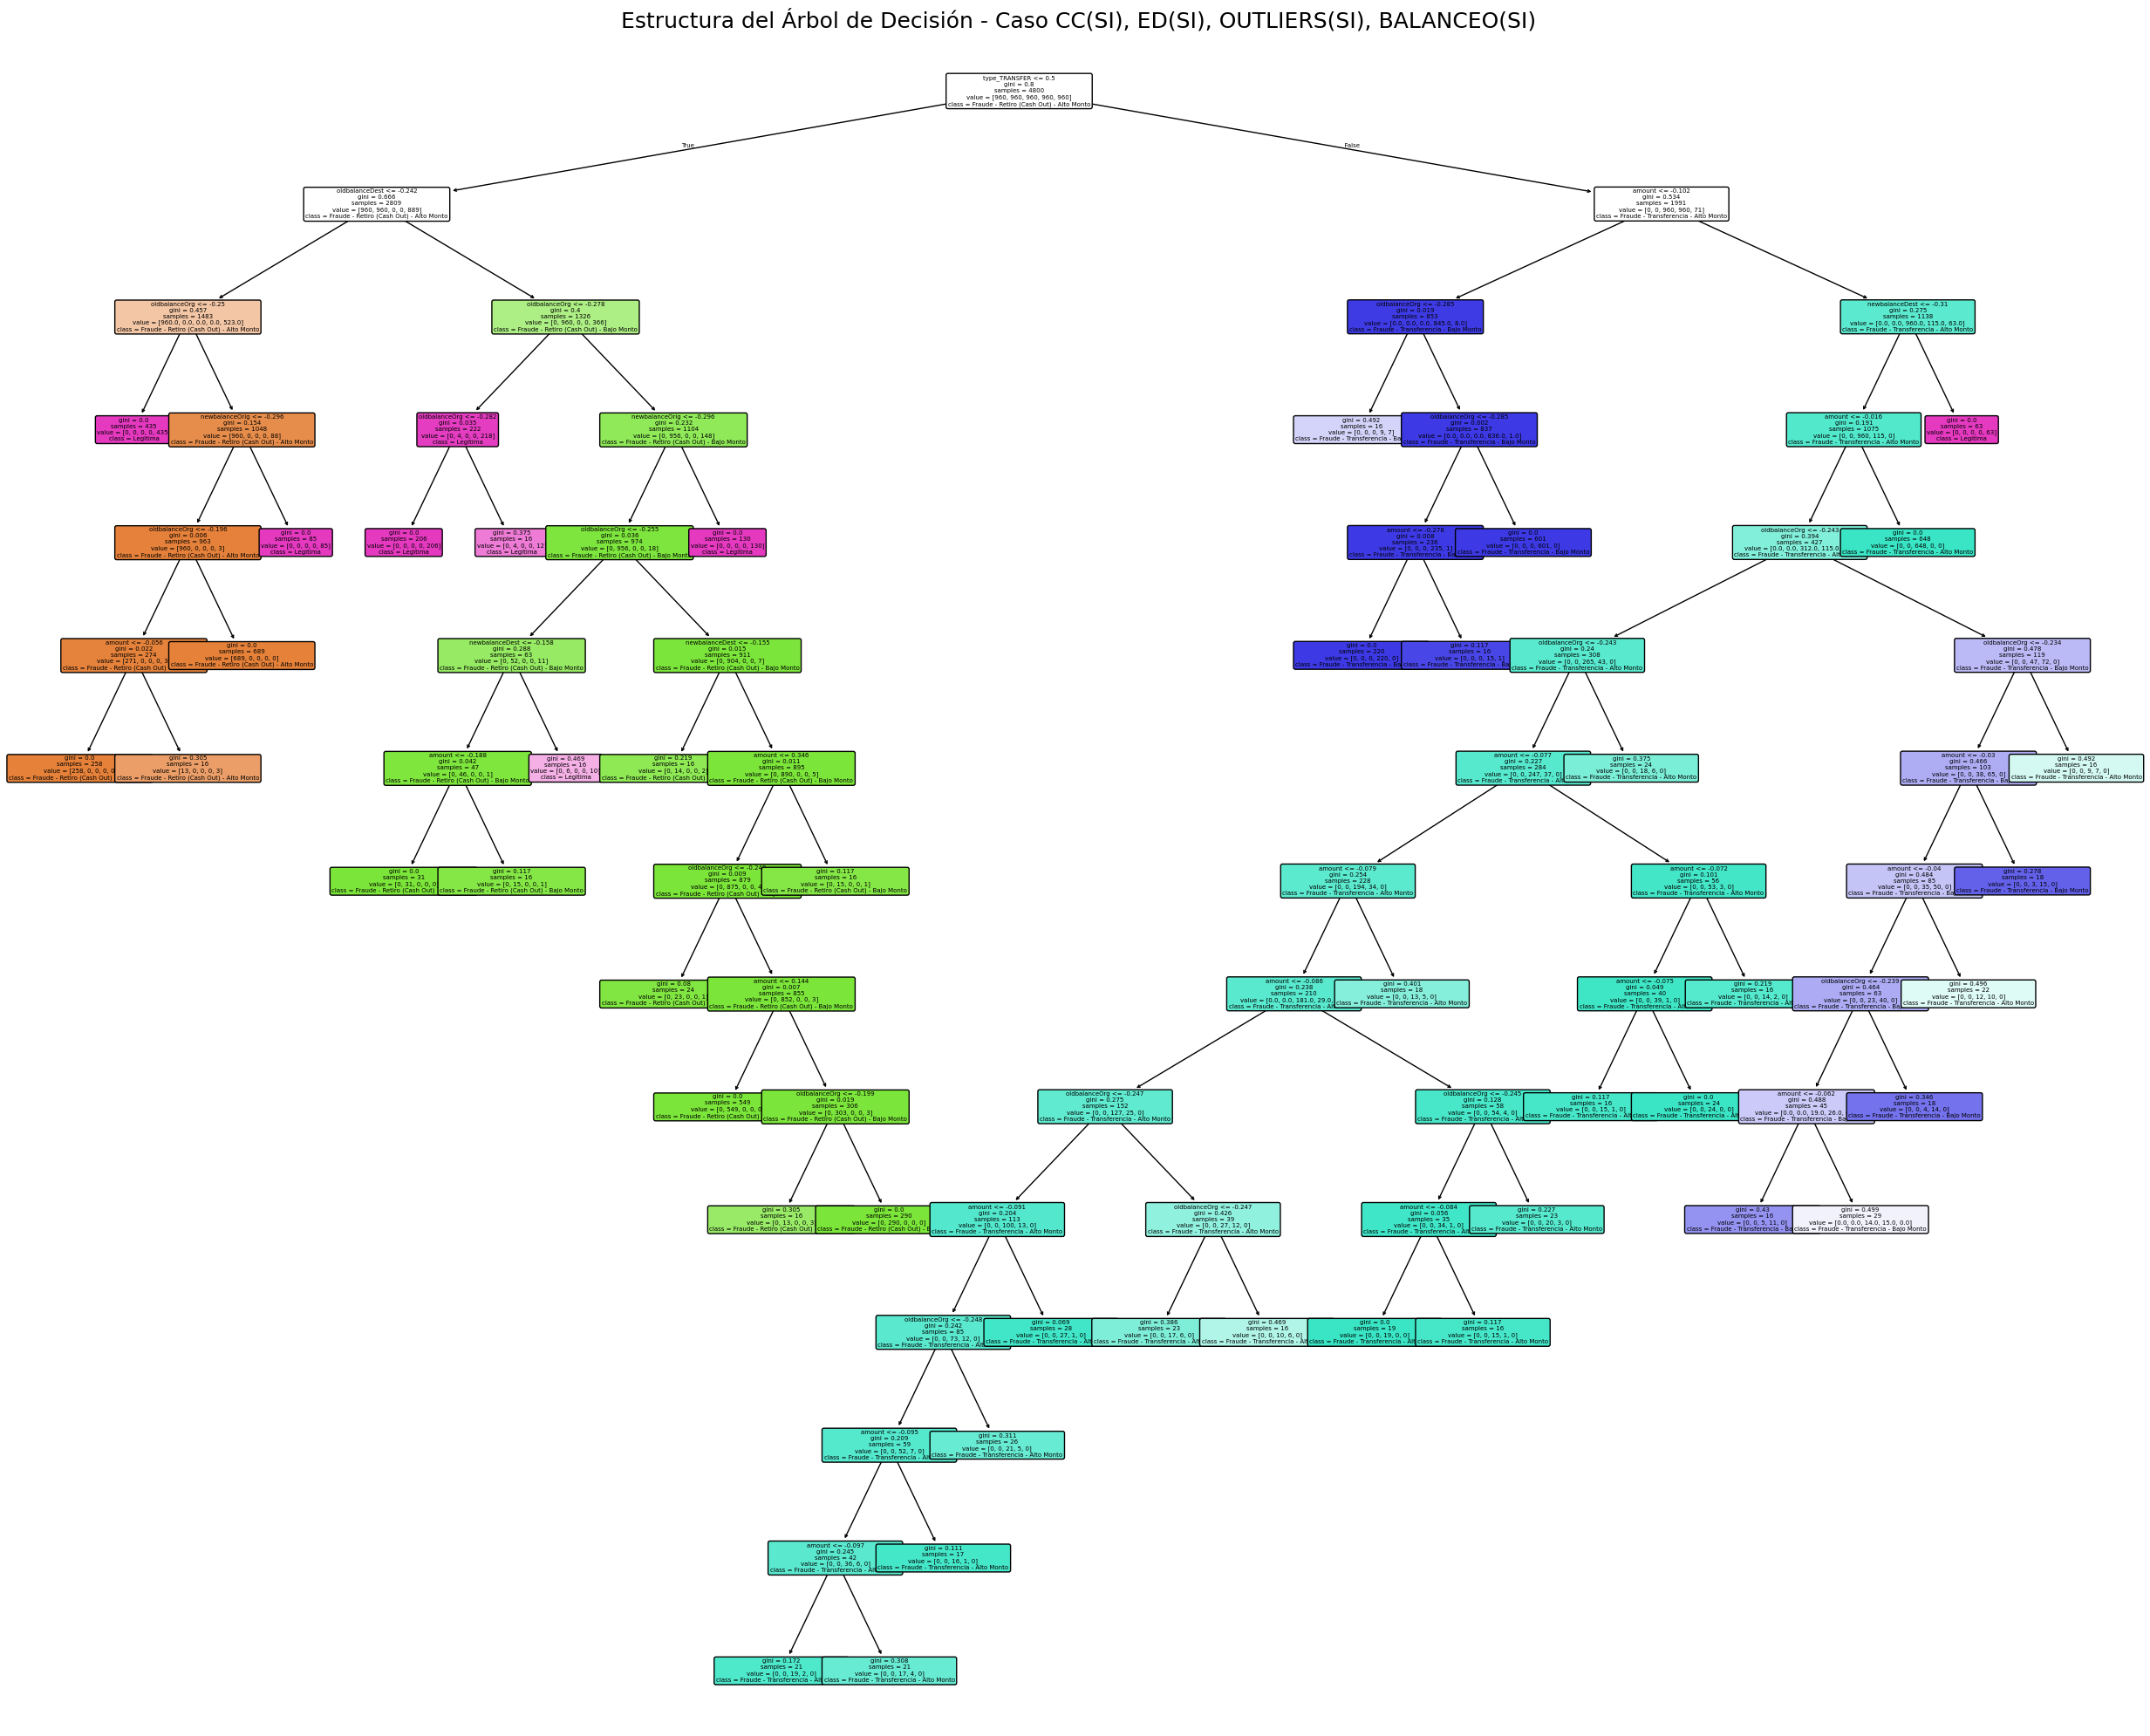

In [29]:
# Las características de entrada (nombres de columnas de X_train)
feature_names = X_train.columns.tolist()

# Los nombres de las clases, en el ORDEN NUMÉRICO en que el modelo los ve (0, 1, 2, 3, 4)
# Asegúrate de que este orden corresponda al mapeo numérico que usaste para y_train_numeric
# unique_classes_sorted ya debería estar en el orden correcto si se usó sorted() para crear el mapeo.
class_names_for_plot = [int_to_class_map[i] for i in sorted(int_to_class_map.keys())]


plt.figure(figsize=(25, 20)) # Ajusta este tamaño según la profundidad y complejidad de tu árbol
                            # Un árbol más profundo requiere una figura más grande

plot_tree(
    tree_classifier,
    filled=True,           # Rellena los nodos con colores para indicar la clase mayoritaria
    feature_names=feature_names, # Nombres de las características para los criterios de división
    class_names=class_names_for_plot, # Nombres de las clases para las hojas
    rounded=True,          # Bordes de los nodos redondeados
    fontsize=5            # Ajusta el tamaño de la fuente si es demasiado pequeño o grande
)


plt.title("Estructura del Árbol de Decisión - Caso CC(SI), ED(SI), OUTLIERS(SI), BALANCEO(SI)", fontsize=18)
plt.tight_layout()
plt.show()

### Curvas ROC & Precision-Recall

Dado que tenemos un caso con multiples clases, lo que vamos a hacer es implementar es usar un enfoque "Uno-contra-el-Resto" (One-vs-Rest, OvR). Esto significa que para cada clase, calculas su curva como si fuera la clase positiva y todas las demás fueran la clase negativa

Clase 'Fraude - Retiro (Cash Out) - Alto Monto':
  AUC-ROC: 1.0000
  AP (Average Precision): 1.0000
Clase 'Fraude - Retiro (Cash Out) - Bajo Monto':
  AUC-ROC: 0.9998
  AP (Average Precision): 0.9988
Clase 'Fraude - Transferencia - Alto Monto':
  AUC-ROC: 0.9977
  AP (Average Precision): 0.9870
Clase 'Fraude - Transferencia - Bajo Monto':
  AUC-ROC: 0.9958
  AP (Average Precision): 0.9891
Clase 'Legitima':
  AUC-ROC: 0.9996
  AP (Average Precision): 0.9979

AUC-ROC General (weighted avg): 0.9986
AUC-ROC General (macro avg): 0.9986
Average Precision (AP) General (weighted avg): 0.9946
Average Precision (AP) General (macro avg): 0.9946


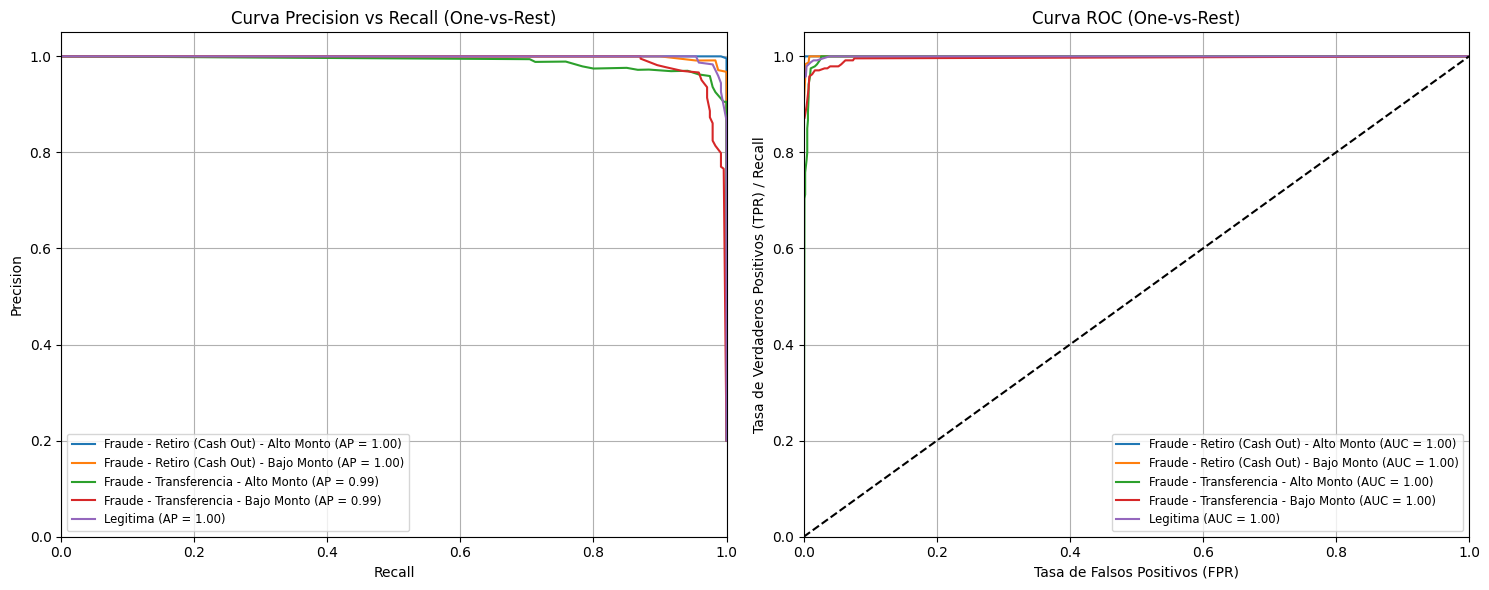

In [34]:
# ==============================================================
# PASO 1: Obtener las probabilidades de predicción para todas las clases

y_pred_proba = tree_classifier.predict_proba(X_test)

# ==============================================================
# PASO 2: Binarizar la variable objetivo de prueba (y_test_numeric) para el enfoque One-vs-Rest
# Esto convierte y_test_numeric (que tiene valores 0,1,2,3,4) en un formato binario para cada clase.
# Ejemplo: si y_test_numeric[i] es 2, entonces y_test_binarized[i, 2] será 1, y el resto 0.
n_classes = len(unique_classes_sorted)
y_test_binarized = label_binarize(y_test_numeric, classes=np.arange(n_classes))

# ==============================================================
# PASO 3: Calcular y almacenar métricas para cada clase (One-vs-Rest)
# y almacenar las curvas para graficar

# Diccionarios para almacenar FPR, TPR, Precision, Recall por clase
fpr = dict()
tpr = dict()
roc_auc = dict()
precision = dict()
recall = dict()
pr_auc = dict()

# Bucle para cada clase
for i in range(n_classes):
    # Curva ROC y AUC
    fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    # Curva Precision-Recall y AP (Average Precision)
    precision[i], recall[i], _ = precision_recall_curve(y_test_binarized[:, i], y_pred_proba[:, i])
    pr_auc[i] = average_precision_score(y_test_binarized[:, i], y_pred_proba[:, i])

    print(f"Clase '{int_to_class_map[i]}':")
    print(f"  AUC-ROC: {roc_auc[i]:.4f}")
    print(f"  AP (Average Precision): {pr_auc[i]:.4f}")

# ==============================================================
# PASO 4: Calcular AUC-ROC y AP promedio (macro/weighted) si se necesitan valores globales para la tabla
# La métrica roc_auc_score ya soporta multi_class directamente

roc_auc_weighted_overall = roc_auc_score(y_test_binarized, y_pred_proba, multi_class='ovr', average='weighted')
roc_auc_macro_overall = roc_auc_score(y_test_binarized, y_pred_proba, multi_class='ovr', average='macro')
print(f"\nAUC-ROC General (weighted avg): {roc_auc_weighted_overall:.4f}")
print(f"AUC-ROC General (macro avg): {roc_auc_macro_overall:.4f}")

# Para Average Precision Score (AP) general, normalmente se promedian los APs por clase
# weighted average AP
pr_auc_weighted_overall = np.average(list(pr_auc.values()), weights=y_test_numeric.value_counts(sort=False))
# macro average AP
pr_auc_macro_overall = np.mean(list(pr_auc.values()))

print(f"Average Precision (AP) General (weighted avg): {pr_auc_weighted_overall:.4f}")
print(f"Average Precision (AP) General (macro avg): {pr_auc_macro_overall:.4f}")


# ==============================================================
# PASO 5: Visualizar las curvas ROC y Precision-Recall
plt.figure(figsize=(15, 6)) # Tamaño de la figura

# --- Curva Precision vs Recall para cada clase ---
plt.subplot(1, 2, 1) # 1 fila, 2 columnas, primer plot
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'{int_to_class_map[i]} (AP = {pr_auc[i]:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision vs Recall (One-vs-Rest)')
plt.grid(True)
plt.legend(loc="lower left", fontsize='small') # Ajusta la leyenda
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])


# --- Curva ROC para cada clase ---
plt.subplot(1, 2, 2) # 1 fila, 2 columnas, segundo plot
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'{int_to_class_map[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--') # Línea diagonal de referencia
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR) / Recall')
plt.title('Curva ROC (One-vs-Rest)')
plt.grid(True)
plt.legend(loc="lower right", fontsize='small') # Ajusta la leyenda
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])


plt.tight_layout() # Ajusta el layout para que no se superpongan los plots
plt.show()


**Análisis Precision vs. Recall**

El modelo mantiene una alta precisión incluso al aumentar el recall, lo que indica un excelente rendimiento: logra detectar más fraudes sin disparar la cantidad de falsos positivos.

Entre recall 0.8 y 1.0 se observa una leve caída en precisión, propia de un criterio más flexible. Sin embargo, esta pérdida es mínima, lo que demuestra que el modelo identifica la mayoría de los fraudes con buena exactitud

En el contexto del dataset, esto nos indica que nuestro modelo es capaz de identificar la mayoría de los casos de fraude y, simultáneamente, cuando clasifica una transacción como fraudulenta, su predicción es casi siempre correcta.

**Análisis de la Curva ROC:**
Cuando la curva ROC de un modelo se aproxima a la esquina superior izquierda del gráfico y el AUC alcanza valores cercanos a 1.0 (como 0.99 en nuestro caso), significa que el modelo es capaz de distinguir con buena precisión entre las distintas clases. Por ejemplo, en la clase Fraude - Retiro Alto Monto, tu modelo alcanzó un AUC de 1.00, lo que indica que puede identificar correctamente este tipo de fraude prácticamente sin confundirlo con otros. Esto equivale a tener un detector que encuentra casi todos los casos reales (recall alto) sin generar falsas alarmas (FPR bajo). Así, el modelo no solo es sensible al fraude, sino también confiable al marcarlo.